# Обзор бизнес-показателей маркетплейса

Автор: Кипенко Илья

**Контекст**: молодой быстрорастущий маркетплейс хочет внедрить аналитику. Имеются данные пользовательского опыта, данные о заказах, данные о товарах и данные по маркетинговым затратам. Команда хочет понять, как чувствует себя продукт: кто приходит, кто остаётся, кто платит, кто уходит. А ещё: на каких каналах держится рост, какие категории товаров приносят деньги, а какие висят мёртвым грузом. Команду интересуют данные за 2024 год. Ранее данные не анализировались.

## <a id="content"></a> Содержание

- [Описание данных](#data_description)
- [Первичный анализ данных](#eda)
- [Фильтрация данных по временному интервалу](#data_filtering)
- [Обзор ключевых метрик](#metrics_analysis)
    - [Выручка и затраты](#total_revenue_costs)
    - [Средняя выручка на пользователя ARPU и на платящего пользователя ARPPU](#arpu_arppu)
    - [Метрики вовлеченности аудитории DAU, MAU, Stickiness](#user_activity)
    - [Динамика конверсии в первую покупку CR](#cr)
    - [Распределение сумм заказов](#order_amount_distribution)
    - [Динамика удержания пользователей](#retention)
    - [Динамика средней суммы заказа AOV](#aov)
    - [Вывод по обзору ключевых метрик](#metrics_conclusion)
- [Анализ юнит-экономики](#unit_economics)
    - [LTV, CAC и ROI с горизонтом событий 60 дней](#ltv_cac_roi_60days)
    - [Когортный анализ окупаемости](#cohort_analysis)
    - [Вывод по анализу юнит-экономики](#unit_economics_conclusion)
- [Анализ в разрезе каналов привлечения](#channel_analysis)
    - [Вывод по анализу в разрезе каналов привлечения](#channel_analysis_conclusion)
- [Анализ воронки](#funnel)
- [Анализ в разрезе устройств пользователей](os_analysis)
- [Анализ в разрезе категорий товаров](#goods_category)
    - [Конверсия в заказ по категориям товаров](#category_cr)
    - [Кластеризация категорий товаров](#category_clustering)
- [RFM-сегментация пользователей](#rfm_segmentation)
    - [Вывод по RFM-сегментации пользователей](#rfm_segmentation_conclusion)
- [Эксперимент - Бонус на первую покупку для пользователей TikTok](#ab_test_tiktok)
    - [Описание эксперимента](#experiment)
    - [Описание данных эксперимента](#data_description)
    - [Первичный анализ данных эксперимента](#ab_data_eda)
    - [Валидация сплиттинга](#ab_splitting_validation)
    - [Проверка метрик эксперимента](#ab_metrics_verification)
    - [Вывод по эксперименту с бонусом на первую покупку для пользователей TikTok](#ab_test_conclusion)

## <a id="data_description"></a> Описание данных

### Таблица `Users`

| Поле              | Описание                                       |
|-------------------|------------------------------------------------|
| `user_id`         | Уникальный идентификатор пользователя.         |
| `registration_date` | Дата регистрации пользователя.                |
| `age`             | Возраст пользователя.                          |
| `gender`          | Пол.                                |
| `region`          | Регион.                                        |
| `acq_channel`     | Канал привлечения.                             |
| `buyer_segment`   | Сегмент покупателя.                            |
| `cohort_week`     | Неделя привлечения.|
| `cohort_month`    | Месяц привлечения. |

---

### Таблица `Events`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `event_id`    | Уникальный идентификатор события.                                        |
| `user_id`     | Идентификатор пользователя.                                              |
| `event_date`  | Дата события.                                                            |
| `event_type`  | Тип события.   |
| `os`          | Операционная система.               |
| `device`      | Тип устройства.                                |
| `product_name`| Наименование товара, к которому относится событие (если применимо).      |
| `event_week`  | Неделя события.                                          |
| `event_month` | Месяц события .                                           |

---

### Таблица `Orders`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `order_id`    | Уникальный идентификатор заказа.                                         |
| `user_id`     | Идентификатор пользователя, который сделал заказ |
| `order_date`  | Дата и время оформления заказа.                                          |
| `product_name`| Наименование товара.                                                     |
| `quantity`    | Количество единиц товара в заказе.                                       |
| `unit_price`  | Цена за одну единицу товара.                                             |
| `total_price` | Итоговая сумма заказа.                                                   |
| `category_name` | Наименование категории товара.                                         |
| `order_week`  | Неделя заказа.                                           |
| `order_month` | Месяц заказа.                                            |


### Таблица `Campaign_costs`

| Поле         | Описание                                                                 |
|--------------|--------------------------------------------------------------------------|
| `acq_channel`| Канал привлечения.  |
| `spend_month`| Месяц, в который был потрачен бюджет (отражает период, в котором были привлечены пользователи)                      |
| `budget`     | Маркетинговый бюджет (в денежном выражении), потраченный на данный канал в указанном месяце.                           |

### Описание event_type таблицы Events

| Событие             | Описание                                                                                  |
|---------------------|-------------------------------------------------------------------------------------------|
| `page_view`         | Открытие любой страницы сайта или приложения пользователем.                                |
| `product_view`      | Просмотр страницы конкретного товара.                                                     |
| `product_click`     | Клик по товару (например, из списка товаров или на баннере).                              |
| `add_to_cart`       | Добавление товара в корзину.                                                              |
| `remove_from_cart`  | Удаление товара из корзины.                                                               |
| `search`            | Выполнение поиска по сайту или приложению.                                                |
| `filter_apply`      | Применение фильтра (например, по цене, бренду, категории).                                |
| `checkout_start`    | Начало оформления заказа (переход к оформлению корзины).                                  |
| `checkout_complete` | Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты).                                          |
| `user_login`        | Вход пользователя в личный кабинет или аккаунт.                                           |
| `user_logout`       | Выход пользователя из аккаунта.                                                           |
| `wishlist_add`      | Добавление товара в список желаемого (wishlist).                                          |
| `category_view`     | Просмотр страницы категории товаров.                                                      |
| `banner_click`      | Клик по рекламному баннеру на сайте или в приложении.                                     |
| `promo_view`        | Просмотр промо-акции или специального предложения.                                        |

### Выручка маркетплейса
Выручка составляет 5% от суммы заказа:<br>
`Revenue = total_price * 0.05`

## <a id="eda"></a> Первичный анализ данных

In [1]:
# импортируем необходимые библиотеки
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import math
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chisquare, ttest_ind, mannwhitneyu
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FixedLocator
import matplotlib.colors as mcolors
import matplotlib.ticker as ticker
import seaborn as sns

In [2]:
# Зададим функцию для первичного анализа датасета
def init_analysis(df, df_name):
    """
    Эта функция автоматизирует шаги первичного анализа датасета:
    1) Выводит первые пять строк датасета
    2) Выводит общую инфромацию о датасете
    3) Выводит асболютное и относитльное кол-во пропусков в столбцах датасета
    4) Выводит статистики количественных столбцов датасета
    5) Считает уникальные значения строковых столбцов датасета
    6) Считает дублированные строки датасета
    
    Как пользоваться: у функции два параметра: датасет df - объект pandas.DataFrame,
    и название датасета df_name в виде строки
    """
    print(f'Выведем первые пять строк датасета {df_name}:')
    display(df.head())
    print('\n')
    
    print(f'Выведем общую информацию о датасете {df_name}:')
    df.info()
    print('\n')
    
    nans = pd.concat([df.isna().sum(), df.isna().sum()/df.shape[0]], axis=1)
    nans.columns = ['NANs_count', 'NANs_share']
    print(f'Выведем абсолютное и относительное кол-во пропусков в столбцах датасета {df_name}:')
    print(nans, end='\n\n')
    
    quantitative_cols_series = (df.dtypes.astype(str).str.contains('float') | df.dtypes.astype(str).str.contains('int'))
    quantitative_cols_list = quantitative_cols_series.loc[quantitative_cols_series == True].index.tolist()
    
    for col in quantitative_cols_list:
        print(f'Статистика столбца {col}:')
        print(df[col].describe(), end='\n\n')
    
    print('\n')
    
    categorical_cols_series = df.dtypes.astype(str).str.contains('object')
    categorical_cols_list = categorical_cols_series.loc[categorical_cols_series == True].index.tolist()
    
    for col in categorical_cols_list:
        print(f'Количество уникальных значений столбца {col}:')
        print(df[col].nunique(), end='\n\n')
    
    print('\n')
    
    datetime_cols_series = df.dtypes.astype(str).str.contains('datetime')
    datetime_cols_list = datetime_cols_series.loc[datetime_cols_series == True].index.tolist()
    
    for col in datetime_cols_list:
        print(f'Интервал дат в столбце {col}: от {df[col].min()} до {df[col].max()}', end='\n\n')
    
    print('\n')
    
    print('Выведем количество дублированных строк:')
    print(df.duplicated().sum())

In [3]:
# функция для читаемой визуализации больших чисел на графиках
def list_numbers_humanize(list):
    humanized_list = []
    for element in list:
        if abs(element) // 1000000 > 0:
            new_element = f'{round(element / 1000000, 1)} M'
        elif abs(element) // 1000 > 0:
            new_element = f'{round(element / 1000, 1)} K'
        else:
            new_element = element
        humanized_list.append(new_element)
    return humanized_list

In [4]:
# зададим функцию для вывода уникальных значений определенных столбцов
def df_columns_uniques(df, columns, print_flag=False):
    columns_uniques = {}
    for column in columns:
        columns_uniques[column] = df[column].unique()
        
        if print_flag:
            print(f"Уникальные значения столбца {column}")
            print(df[column].unique())
            print('\n')
    return columns_uniques

In [5]:
# зададим функцию для преобразования значений pie plot из долей в асболютные
def absolute_value(pct, allvals):
    absolute = int(round(pct/100.*np.sum(allvals)))
    return f'{absolute}'

In [6]:
# зададим функцию для создания объекта map для задания одинаковых цветов категорий на разных графиках 
def get_colors(labels, mapping):
    return [mapping[label] for label in labels]

In [7]:
# Зададим функцию для сокращения записи больших чисел при выведении графиков
def human_readable(val):
    if pd.isna(val) or val == 0:
        return '0'
    
    suffixes = ['', 'K', 'M', 'B', 'T']
    magnitude = 0
    
    while abs(val) >= 1000 and magnitude < len(suffixes) - 1:
        val /= 1000.0
        magnitude += 1
        
    return f"{val:.2f}{suffixes[magnitude]}"

In [8]:
# зададим функцию для определения границ карзин гистограмм с кратностью
def bin_edge(range_min, range_max, bin_width):
    bins_left_edge = math.floor(range_min / bin_width) * bin_width
    bins_right_edge = math.ceil(range_max / bin_width) * bin_width
    bins = list(range(bins_left_edge, bins_right_edge + 1, bin_width))
    return bins

In [9]:
# загрузим датасеты
pa_marketplace_orders = pd.read_csv('datasets/pa_marketplace_orders.csv', parse_dates=['order_date', 'order_week', 'order_month'])
pa_marketplace_campaign_costs = pd.read_csv('datasets/pa_marketplace_campaign_costs.csv', parse_dates=['spend_month'])
pa_marketplace_users = pd.read_csv('datasets/pa_marketplace_users.csv', parse_dates=['cohort_week', 'cohort_month', 'registration_date'])
pa_marketplace_events = pd.read_csv('datasets/pa_marketplace_events.csv', parse_dates=['event_date', 'event_week', 'event_month'])

Первичный анализ данных датасета `pa_marketplace_orders.csv`:

In [10]:
init_analysis(pa_marketplace_orders, 'pa_marketplace_orders')

Выведем первые пять строк датасета pa_marketplace_orders:


,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01




Выведем общую информацию о датасете pa_marketplace_orders:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31357 entries, 0 to 31356
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       31357 non-null  int64         
 1   user_id        31357 non-null  int64         
 2   order_date     31357 non-null  datetime64[ns]
 3   product_name   31357 non-null  object        
 4   quantity       31357 non-null  int64         
 5   unit_price     31357 non-null  float64       
 6   total_price    31357 non-null  float64       
 7   category_name  31357 non-null  object        
 8   order_week     31357 non-null  datetime64[ns]
 9   order_month    31357 non-null  datetime64[ns]
dtypes: datetime64[ns](3), float64(2), int64(3), object(2)
memory usage: 2.4+ MB


Выведем абсолютное и относительное кол-во пропусков в столбцах датасета pa_marketplace_orders:
               NANs_count  NANs_share
or

Проверим, нет ли дублированных заказов по комбинации id пользователя и времени-даты заказа:

In [11]:
user_date_duplicated = pa_marketplace_orders.duplicated(subset=['user_id', 'order_date']).sum()
print(f'Кол-во дублированных комбинаций `user_id` - `order_date` = {user_date_duplicated}.')

Кол-во дублированных комбинаций `user_id` - `order_date` = 13341.


Такой эффект объясняется тем, что идентификатор `order_id` присваивается каждой позиции в заказе клиента: на примере первых пяти выведенных строк, пользователем с `user_id` = 3 в момент времени `order_date` = `2024-01-19 01:52:52.000` совершено три заказа с `order_id` = 1, 2, 3 с позициями 'Шуруповерт' (2 шт.), 'Молоток слесарный' (1 шт) и 'Секатор садовый' (2 шт.). Фактически пользователь совершил один заказ, но при сборе данных они разбиваются на три. Это наблюдение может быть важным для анализа покупательского поведения пользователей.
___
Выведем уникальные значения категориальных столбцов датасета `pa_marketplace_orders`:

In [12]:
categorial_columns = ['category_name']
columns_uniques = df_columns_uniques(pa_marketplace_orders, categorial_columns)
sorted(columns_uniques['category_name'])

['Автотовары',
 'Аксессуары для гаджетов',
 'Бытовая техника',
 'Декор и освещение',
 'Детская одежда',
 'Детские игрушки',
 'Женская одежда',
 'Зоотовары',
 'Инструменты и садовый инвентарь',
 'Книги и канцтовары',
 'Косметика и парфюмерия',
 'Мебель для дома',
 'Медицинские товары',
 'Мужская одежда',
 'Обувь женская',
 'Обувь мужская',
 'Одежда для спорта',
 'Продукты питания',
 'Спортивный инвентарь',
 'Средства для ухода',
 'Сумки и аксессуары',
 'Товары для кухни',
 'Товары для новорожденных',
 'Товары для туризма',
 'Украшения и часы']

В столбце `category_name` нет неявных дубликатов.

In [13]:
product_name_uniques = pa_marketplace_orders['product_name'].unique().tolist()
product_name_uniques_lower_strip = list(map(lambda x: x.lower().strip(), product_name_uniques))

print(f'Кол-во уникальных значений `product_name` = {len(product_name_uniques)}')
print(f'Кол-во уникальных значений `product_name` после перевода в нижний регистр и удаления пробелов = {len(product_name_uniques_lower_strip)}')

Кол-во уникальных значений `product_name` = 200
Кол-во уникальных значений `product_name` после перевода в нижний регистр и удаления пробелов = 200


Проверка неявных дубликатов в `product_name` методом удаления пробелов и перевода символов в нижний регистр не выявила дубликаты в столбце.

___
Первичный анализ данных датасета `pa_marketplace_campaign_costs`:

In [14]:
init_analysis(pa_marketplace_campaign_costs, 'pa_marketplace_campaign_costs')

Выведем первые пять строк датасета pa_marketplace_campaign_costs:


,Unnamed: 0,acq_channel,spend_month,budget
0,0,Affiliate,2024-01-01,179343.3875
1,1,Affiliate,2024-02-01,175488.4875
2,2,Affiliate,2024-03-01,164543.4750
3,3,Affiliate,2024-04-01,186869.9750
4,4,Affiliate,2024-05-01,166443.7750




Выведем общую информацию о датасете pa_marketplace_campaign_costs:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Unnamed: 0   88 non-null     int64         
 1   acq_channel  88 non-null     object        
 2   spend_month  88 non-null     datetime64[ns]
 3   budget       88 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 2.9+ KB


Выведем абсолютное и относительное кол-во пропусков в столбцах датасета pa_marketplace_campaign_costs:
             NANs_count  NANs_share
Unnamed: 0            0         0.0
acq_channel           0         0.0
spend_month           0         0.0
budget                0         0.0

Статистика столбца Unnamed: 0:
count    88.000000
mean     43.500000
std      25.547342
min       0.000000
25%      21.750000
50%      43.500000
75%      65.250000
max 

In [15]:
categorial_columns = ['acq_channel']
columns_uniques = df_columns_uniques(pa_marketplace_campaign_costs, categorial_columns)
sorted(columns_uniques['acq_channel'])

['Affiliate',
 'Direct',
 'Email Marketing',
 'Google Ads',
 'SEO',
 'Social Media',
 'TikTok']

В столбце каналов привлечения неявных дубликатов не обнаружено.

Проведем первичный анализ датасета `pa_marketplace_users`

In [16]:
init_analysis(pa_marketplace_users, 'pa_marketplace_users')

Выведем первые пять строк датасета pa_marketplace_users:


,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,1,2024-01-01 00:47:00,35,M,Москва,Google Ads,regular,2024-01-01,2024-01-01
1,2,2024-01-01 19:01:00,53,M,Москва,Email Marketing,rare,2024-01-01,2024-01-01
2,3,2024-01-01 04:13:00,66,F,Санкт-Петербург,Google Ads,regular,2024-01-01,2024-01-01
3,4,2024-01-01 17:18:00,58,M,Краснодар,Affiliate,one_time,2024-01-01,2024-01-01
4,5,2024-01-01 08:29:00,58,F,Другие регионы,Google Ads,regular,2024-01-01,2024-01-01




Выведем общую информацию о датасете pa_marketplace_users:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            44151 non-null  int64         
 1   registration_date  44151 non-null  datetime64[ns]
 2   age                44151 non-null  int64         
 3   gender             44151 non-null  object        
 4   region             44151 non-null  object        
 5   acq_channel        44151 non-null  object        
 6   buyer_segment      44151 non-null  object        
 7   cohort_week        44151 non-null  datetime64[ns]
 8   cohort_month       44151 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 3.0+ MB


Выведем абсолютное и относительное кол-во пропусков в столбцах датасета pa_marketplace_users:
                   NANs_count  NANs_share
user_id             

In [17]:
pa_marketplace_users.duplicated(subset=['user_id']).sum()

np.int64(0)

Выведем уникальные значения категориальных столбцов

In [18]:
categorial_columns = ['region', 'acq_channel', 'buyer_segment']
columns_uniques = df_columns_uniques(pa_marketplace_users, categorial_columns)
for key in columns_uniques.keys():
    print(sorted(columns_uniques[key]), end='\n\n')

['Другие регионы', 'Екатеринбург', 'Краснодар', 'Москва', 'Московская область', 'Нижний Новгород', 'Новосибирск', 'Ростов-на-Дону', 'Санкт-Петербург']

['Affiliate', 'Email Marketing', 'Google Ads', 'SEO', 'Social Media', 'TikTok']

['medium', 'one_time', 'rare', 'regular']



Проведем первичный анализ датасета `pa_marketplace_events`

In [19]:
init_analysis(pa_marketplace_events, 'pa_marketplace_events')

Выведем первые пять строк датасета pa_marketplace_events:


,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01




Выведем общую информацию о датасете pa_marketplace_events:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785859 entries, 0 to 785858
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      785859 non-null  int64         
 1   user_id       785859 non-null  int64         
 2   event_date    785859 non-null  datetime64[ns]
 3   event_type    785859 non-null  object        
 4   os            785859 non-null  object        
 5   device        785859 non-null  object        
 6   product_name  385740 non-null  object        
 7   event_week    785859 non-null  datetime64[ns]
 8   event_month   785859 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 54.0+ MB


Выведем абсолютное и относительное кол-во пропусков в столбцах датасета pa_marketplace_events:
              NANs_count  NANs_share
event_id               0    0.000000
user_id                0   

Выведем уникальные значения категориальных столбцов

In [20]:
categorial_columns = ['event_type', 'os', 'device']
columns_uniques = df_columns_uniques(pa_marketplace_events, categorial_columns)
for key in columns_uniques.keys():
    print(sorted(columns_uniques[key]), end='\n\n')

['add_to_cart', 'banner_click', 'category_view', 'checkout_complete', 'checkout_start', 'filter_apply', 'page_view', 'product_click', 'product_view', 'promo_view', 'remove_from_cart', 'search', 'user_login', 'user_logout', 'wishlist_add']

['Android', 'Windows', 'iOS', 'macOS']

['desktop', 'mobile', 'tablet']



Проведен первичный анализ данных.
- Типы данных соответствуют содержащейся в столбцах информации. Столбцы с датами предзагружены в формате datetime.
- Пропуски в столбце `product_name` датасета `pa_marketplace_events` допустимы.
- В датасете `pa_marketplace_campaign_costs` есть записи, выходящие за 2024 год - их нужно отфильтровать.
- В датасетах нет явных и неявных дубликатов.
- Наименования столбцов исполнены в одном стиле `snake_case`, что удобно для работы.
- Судя по первому знакомству с данными, значения в столбцах соответствуют их описанию.

## <a id="data_filtering"></a> Фильтрация данных по временному интервалу

In [21]:
start_date = pd.Timestamp('2024-01-01')
end_date = pd.Timestamp('2024-12-31')

# отфильтруем данные по временному интералу 2024 года

pa_marketplace_events = pa_marketplace_events.loc[pa_marketplace_events['event_date'].between(start_date, end_date)]
pa_marketplace_orders = pa_marketplace_orders.loc[pa_marketplace_orders['order_date'].between(start_date, end_date)]
pa_marketplace_campaign_costs = pa_marketplace_campaign_costs.loc[pa_marketplace_campaign_costs['spend_month'].between(start_date, end_date)]
pa_marketplace_users = pa_marketplace_users.loc[pa_marketplace_users['cohort_month'].between(start_date, end_date)]

## <a id="metrics_analysis"></a> Обзор ключевых метрик

### <a id="total_revenue_costs"></a> Выручка и затраты

In [22]:
# посчитаем выручку с каждого заказа в датасете pa_marketplace_orders
pa_marketplace_orders['order_revenue'] = pa_marketplace_orders['total_price'] * 0.05

Рассчитаем обшую выручку и затраты за 2024 год:

In [23]:
total_revenue = pd.DataFrame({'2024': pa_marketplace_orders['order_revenue'].sum()}, index=['total_revenue'])

total_costs = pd.DataFrame({'2024': pa_marketplace_campaign_costs['budget'].sum()}, index=['total_costs'])

total_sums = pd.concat([total_revenue, total_costs])

total_sums = total_sums.reset_index()

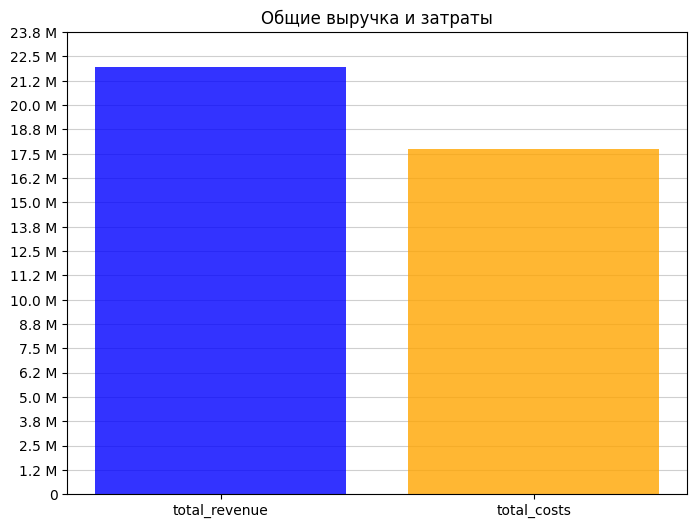

In [24]:
# построим столбчатую диаграмму общих выручки и затрат 
plt.figure(figsize=(8, 6))

plt.bar(total_sums['index'], total_sums['2024'], color=['blue', 'orange'], alpha=0.8, zorder=2)

plt.grid(axis='y', alpha=0.6)
plt.yticks(ticks=range(0, 25000000, 1250000),
           labels=list_numbers_humanize(list(range(0, 25000000, 1250000))))

plt.title('Общие выручка и затраты')
plt.show()

Общая выручка выше суммарных затрат - бизнес не в убытке.

___
Посмотрим на динамику выручки и затрат по месяцам:

In [25]:
# посчитаем выручку по месяцам
month_revenue = pa_marketplace_orders.groupby('order_month').agg(
    month_revenue=('order_revenue', 'sum')
).reset_index()

In [26]:
# посчитаем маркетинговые затраты по месяцам
costs_month = pa_marketplace_campaign_costs.groupby('spend_month')['budget'].sum().reset_index()

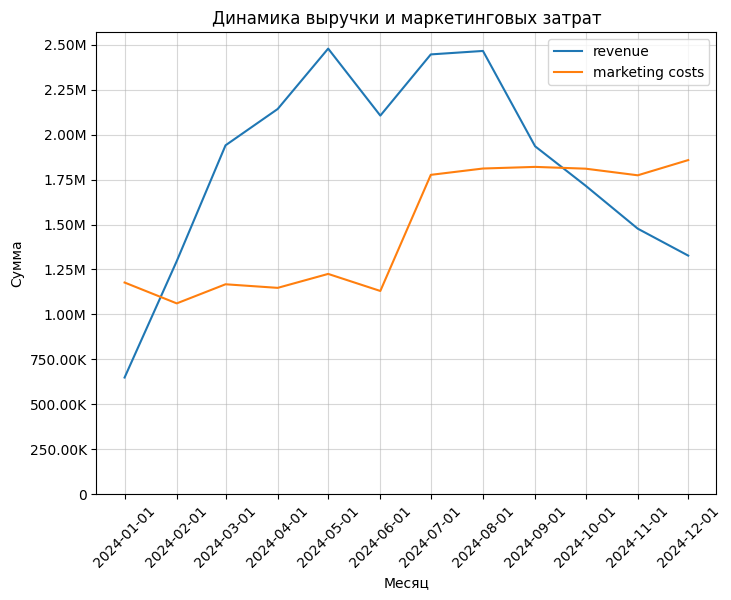

In [27]:
# потроим график данамики выручки и затрат по месяцам
plt.figure(figsize=(8, 6))

start_date = pd.Timestamp('2024-01-01')
end_date = pd.Timestamp('2024-12-31')
month_dates = pd.date_range(start=start_date, end=end_date, freq='MS')
month_tick_locations = mdates.date2num(month_dates)

plt.plot(month_revenue['order_month'], month_revenue['month_revenue'], label='revenue')
plt.plot(costs_month['spend_month'], costs_month['budget'], label='marketing costs')

ax = plt.gca()
ax.xaxis.set_major_locator(FixedLocator(month_tick_locations))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.grid(alpha=0.5)
ax.tick_params(axis='x', labelrotation=45)

plt.yticks(ticks=range(0, 2750000, 250000), labels=(human_readable(number) for number in list(range(0, 2750000, 250000))))
plt.legend()
plt.xlabel('Месяц')
plt.ylabel('Сумма')
plt.title('Динамика выручки и маркетинговых затрат')
plt.show()

- Выручка растет примерно до мая, стагнирует до августа и падает до конца года.
- Затраты на маркетинг постоянны до июня, скачкообразно увеличиваются в июле, после чего остаются постоянными на новом июльском уровне.
- Выручка выше маркетинговых затрат с февраля, но падение выручки в конце года и рост затрат с июля привели к тому, что с октября бизнес несет убытки.

### <a id="arpu_arppu"></a> Средняя выручка на пользователя ARPU и на платящего пользователя ARPPU

In [28]:
# подсчитаем кол-во пользователей по месяцам
month_active_users = pa_marketplace_events.groupby('event_month')['user_id'].nunique().reset_index()
month_active_users.rename(columns={'event_month': 'month', 'user_id': 'users_count'}, inplace=True)

In [29]:
# подсчитаем кол-во платящих пользователей и выручку по месяцам
month_revenue_user = pa_marketplace_orders.groupby(['order_month']).agg(
    month_revenue=('order_revenue', 'sum'),
    paying_users_count=('user_id', 'nunique')
).reset_index()

month_revenue_user.rename(columns={'order_month': 'month'}, inplace=True)

# объединим датафреймы с выручкой по месяцам и пользователями
month_revenue_user = month_revenue_user.merge(month_active_users, on='month')

In [30]:
# расчитаем ARPU и ARPPU
month_revenue_user['ARPPU'] = month_revenue_user['month_revenue'] / month_revenue_user['paying_users_count']
month_revenue_user['ARPU'] = month_revenue_user['month_revenue'] / month_revenue_user['users_count']

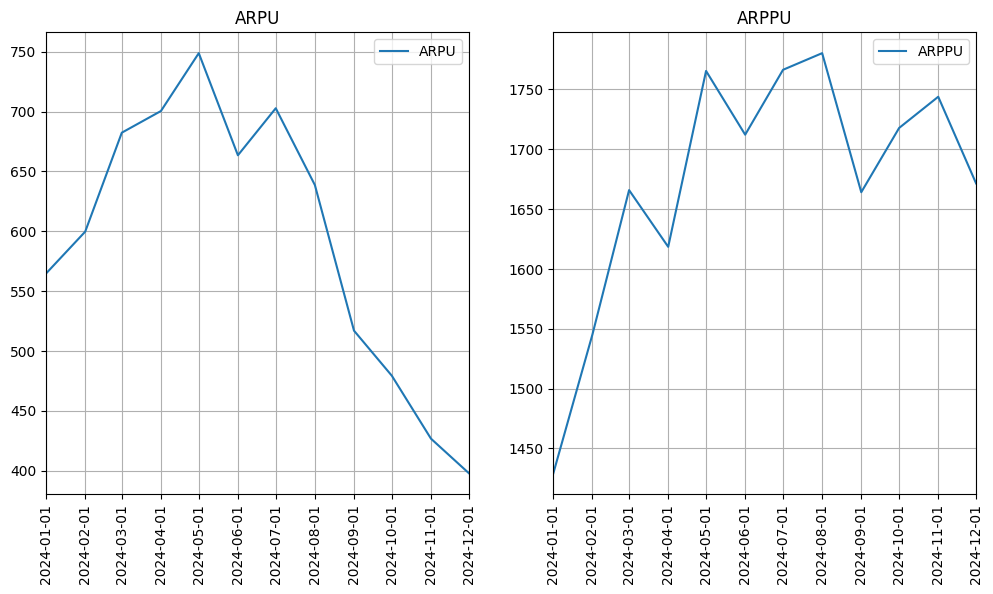

In [31]:
# построим график ARPU и ARPPU
fig, ax = plt.subplots(1, 2, figsize=(12,6))

start_date = pd.Timestamp('2024-01-01')
end_date = pd.Timestamp('2024-12-01')

dates = pd.date_range(start=start_date, end=end_date, freq='MS')
tick_locations = mdates.date2num(dates)

ax[0].plot(month_revenue_user['month'], month_revenue_user['ARPU'], label='ARPU')
ax[0].xaxis.set_major_locator(FixedLocator(tick_locations))
ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax[0].tick_params(axis='x', labelrotation=90)
ax[0].set_title('ARPU')
ax[0].legend()
ax[0].grid()
ax[0].set_xlim(start_date, end_date)
# ax[0].set_ylim(0, month_revenue_user['ARPU'].max() * 1.05)

ax[1].plot(month_revenue_user['month'], month_revenue_user['ARPPU'], label='ARPPU')
ax[1].xaxis.set_major_locator(FixedLocator(tick_locations))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax[1].tick_params(axis='x', labelrotation=90)
ax[1].set_title('ARPPU')
ax[1].legend()
ax[1].grid()
ax[1].set_xlim(start_date, end_date)
# ax[1].set_ylim(0, month_revenue_user['ARPPU'].max() * 1.05)

plt.show()

- ARPU растет с начала года до мая на 30 %, после чего резко падает. К концу года метрика опускается до уровня 400, что ниже показателя января на 175 или на 30 %.
- ARPPU ростет с начала года до мая на ~20 %, после чего метрика остается на постоянном уровне.

### <a id="user_activity"></a> Метрики вовлеченности аудитории DAU, MAU, Stickiness

In [32]:
# рассчитаем показатели dau и mau
dau = pa_marketplace_events.groupby(['event_date', 'event_month']).agg(dau=('user_id', 'nunique')).reset_index()
dau['dau_rolling_7days'] = dau['dau'].rolling(7).mean()
mau = pa_marketplace_events.groupby('event_month').agg(mau=('user_id', 'nunique')).reset_index()

In [33]:
# рассчитаем метрику stickiness
stickiness = dau.groupby('event_month').agg(avg_dau=('dau', 'mean')).reset_index()
stickiness = stickiness.merge(mau, on='event_month')
stickiness['stickiness'] = 100 * stickiness['avg_dau'] / stickiness['mau']

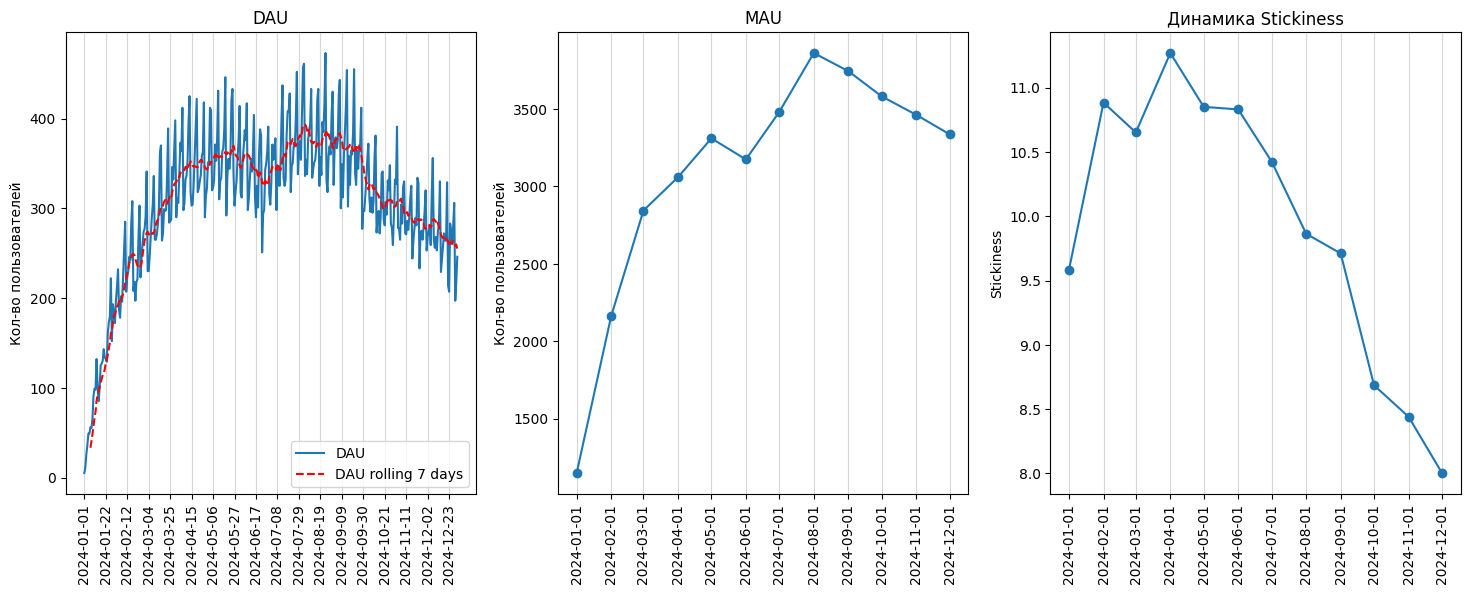

In [34]:
# построим график динамики dau, mau, stickiness
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

start_date = pd.Timestamp('2024-01-01')
end_date = pd.Timestamp('2024-12-31')

dates = pd.date_range(start=start_date, end=end_date, freq='3W-MON')
tick_locations = mdates.date2num(dates)

month_dates = pd.date_range(start=start_date, end=end_date, freq='MS')
month_tick_locations = mdates.date2num(month_dates)

ax[0].plot(dau['event_date'], dau['dau'], label='DAU')
ax[0].plot(dau['event_date'], dau['dau_rolling_7days'], label='DAU rolling 7 days', ls='--', c='red')
ax[0].legend()

ax[0].tick_params(axis='x', labelrotation=90)
ax[0].set_ylabel('Кол-во пользователей')
ax[0].set_title('DAU')
ax[0].xaxis.set_major_locator(FixedLocator(tick_locations))
ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax[0].grid(axis='x', alpha=0.5)

ax[1].plot(mau['event_month'], mau['mau'], marker='o')
ax[1].tick_params(axis='x', labelrotation=90)
ax[1].set_ylabel('Кол-во пользователей')
ax[1].set_title('MAU')
ax[1].xaxis.set_major_locator(FixedLocator(month_tick_locations))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax[1].grid(axis='x', alpha=0.5)

ax[2].plot(stickiness['event_month'], stickiness['stickiness'], marker='o')
ax[2].tick_params(axis='x', labelrotation=90)
ax[2].set_ylabel('Stickiness')
ax[2].set_title('Динамика Stickiness')
ax[2].xaxis.set_major_locator(FixedLocator(month_tick_locations))
ax[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax[2].grid(axis='x', alpha=0.5)

plt.show()

- Дневная аудитория стремительно растет с начала года до середины апреля, выходит на плато до сентября, после чего падает.
- Ежемесячная показывает значительный рост до августа с последующим уменьшением показателя до конца года.
- Метрика "липкости", показывающая то, как вовлечена аудитория втечение месяца, указывает на то, что не смотря на рост ежемечной аудитории, с апреля "качество" пользователей падает - приходят менее активные пользователи.

### <a id="cr"></a> Динамика конверсии в первую покупку CR 

Посчитаем конверсию в первую покупку по месяцам. Для этого будем учитывать пользовалей, совешивших покупку втечение 60 дней с момента регистрации.

In [35]:
# рассчитаем конверсию в покупку при lifetime 60 дней
pa_marketplace_orders['order_time'] = pa_marketplace_orders['order_date'].dt.time
pa_marketplace_orders['order_date'] = pd.to_datetime(pa_marketplace_orders['order_date'].dt.date)

pa_marketplace_orders = pa_marketplace_orders.merge(pa_marketplace_users[['user_id', 'registration_date', 'cohort_month']], on='user_id')
pa_marketplace_orders['registration_date'] = pd.to_datetime(pa_marketplace_orders['registration_date'].dt.date) 

pa_marketplace_orders['lifetime'] = pa_marketplace_orders['order_date'].dt.to_period('D').astype('int64') - pa_marketplace_orders['registration_date'].dt.to_period('D').astype('int64')

CR_dynamic = pa_marketplace_orders.loc[pa_marketplace_orders['lifetime'] <= 60].groupby('cohort_month').agg(
    target_users=('user_id', 'nunique')
).reset_index()

attr_users_dynamic = pa_marketplace_users.groupby('cohort_month').agg(
    attr_users=('user_id', 'count')
).reset_index()

CR_dynamic = CR_dynamic.merge(attr_users_dynamic, on='cohort_month', how='right')

CR_dynamic['CR'] = 100 * CR_dynamic['target_users'] / CR_dynamic['attr_users']

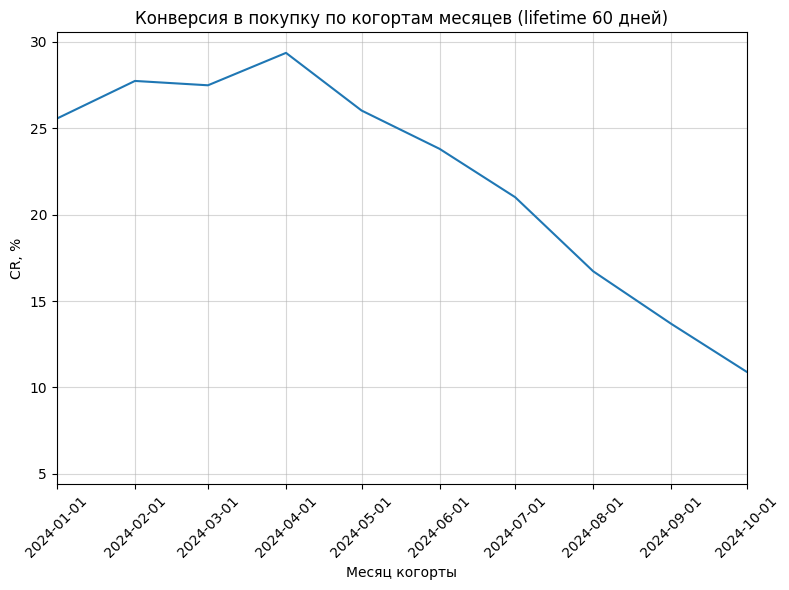

In [36]:
# построим график динамики конверсии
plt.figure(figsize=(8, 6))

start_date = pd.Timestamp('2024-01-01')
end_date = pd.Timestamp('2024-12-31')

plt.plot(CR_dynamic['cohort_month'], CR_dynamic['CR'])

ax = plt.gca()

dates = pd.date_range(start=start_date, end=end_date, freq='MS')
tick_locations = mdates.date2num(dates)

month_dates = pd.date_range(start=start_date, end=end_date, freq='MS')
month_tick_locations = mdates.date2num(month_dates)

ax.xaxis.set_major_locator(FixedLocator(month_tick_locations))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.xaxis.set_minor_locator(ticker.NullLocator())
ax.grid(alpha=0.5)
ax.tick_params(axis='x', labelrotation=45)

plt.xlim(start_date, pd.Timestamp('2024-10-01'))
plt.xlabel('Месяц когорты')
plt.ylabel('CR, %')
plt.title('Конверсия в покупку по когортам месяцев (lifetime 60 дней)')
plt.tight_layout()
plt.show()

Конверсия в покупку растет до апреля, достигая почти 30 %, после чего монотонно падает, опускаясь до 10 % к концу года

### <a id="order_amount_distribution"></a> Распределение сумм заказов

In [37]:
# подсчитаем суммы заказов. В заказе будем учитывать все позиции, оплаченные пользователем одномоментно 
order_value_distribution = pa_marketplace_orders.groupby(['user_id', 'order_date'])['total_price'].sum().reset_index()

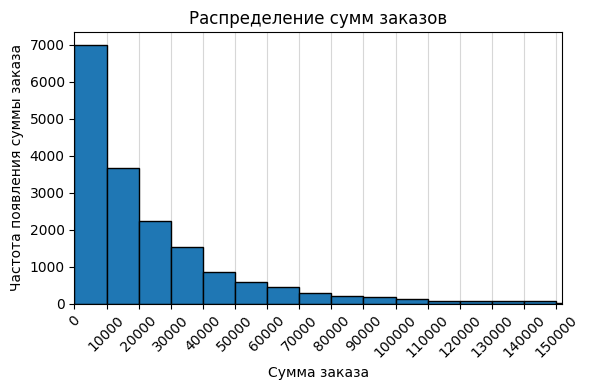

1 квартиль распределения суммы заказов = 5977.0
Медиана распределения суммы заказов = 13875.22
3 квартиль распределения суммы заказов = 31154.22
95% интервал от 1031.0 до 109028.0


In [38]:
# построим гистограмму сумм заказов
plt.figure(figsize=(6, 4))

bins = list(range(0, 210000, 10000))

plt.hist(order_value_distribution.loc[order_value_distribution['total_price'] <= np.percentile(order_value_distribution['total_price'], 99)]['total_price'],
         zorder=2, edgecolor='black', bins=bins)

plt.grid(axis='x', alpha=0.5)

plt.xticks(bins, rotation=45)
plt.xlim(0, np.percentile(order_value_distribution['total_price'], 99))
plt.xlabel('Сумма заказа')
plt.ylabel('Частота появления суммы заказа')
plt.title('Распределение сумм заказов')
plt.tight_layout()
plt.show()

# Выведем квартили распределения
q1 = order_value_distribution['total_price'].quantile(q=0.25)
q2 = order_value_distribution['total_price'].quantile(q=0.50)
q3 = order_value_distribution['total_price'].quantile(q=0.75)
two_sigma_left = order_value_distribution['total_price'].quantile(q=0.025)
two_sigma_right = order_value_distribution['total_price'].quantile(q=0.975)

print(f'1 квартиль распределения суммы заказов = {round(q1, 0)}')
print(f'Медиана распределения суммы заказов = {round(q2, 2)}')
print(f'3 квартиль распределения суммы заказов = {round(q3, 2)}')
print(f'95% интервал от {round(two_sigma_left, 0)} до {round(two_sigma_right, 0)}')

Распределение сумм заказов сильно скошено влево - большинство пользователей совершают недорогие покупки, при этом есть сегмент пользователей, совершающих дорогостоящие покупки. При медианном значении в 14 тысяч рублей, 75 % пользователей совершают покупки на сумму до 31 тысячи, 20 % пользователей в правой части распределения совершают покупки от 31 до 110 тысяч рублей, и 5 % пользователей в правом хвосте совершают покупки до от 110 до 150 тысяч. 

### <a id="retention"></a> Динамика удержания пользователей

In [39]:
# сформируем в датасете pa_marketplace_events столбец n_period для построения heatmap
pa_marketplace_events = pa_marketplace_events.merge(pa_marketplace_users[['user_id', 'cohort_month']], on='user_id')

pa_marketplace_events['n_period'] = (
    pa_marketplace_events['event_month'].dt.to_period('M').astype('int64')
    - pa_marketplace_events['cohort_month'].dt.to_period('M').astype('int64')
)


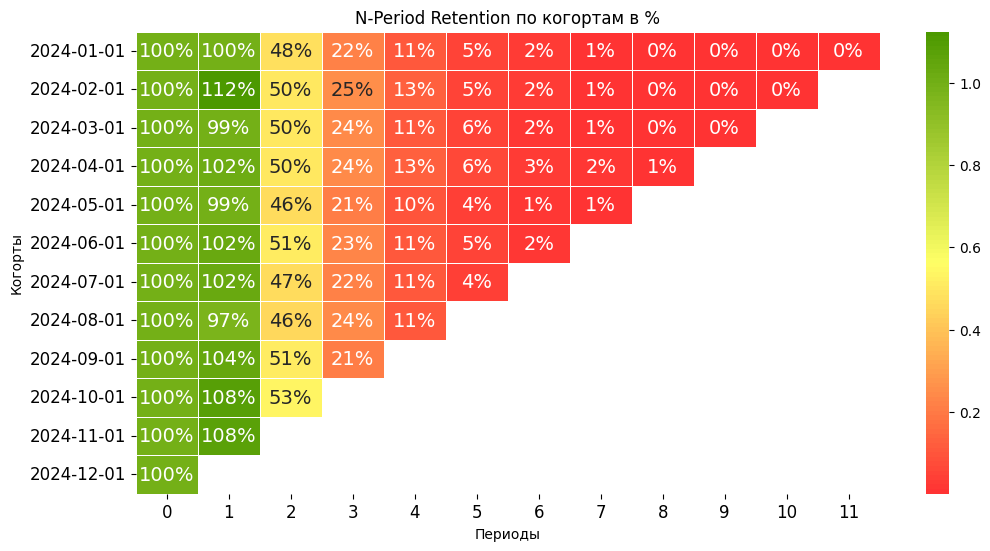

In [40]:
# Построим сводную таблицу, посчитаем кол-во уникальных пользователей в когорте по месяцам 
data_pivot = pd.pivot_table(pa_marketplace_events,
                            values='user_id',
                            index='cohort_month',
                            columns='n_period',
                            aggfunc=pd.Series.nunique).fillna(0).astype(int)

data_pivot = data_pivot.replace('', 0).astype('int')

data_pivot = data_pivot.div(data_pivot[0], axis=0)

data_pivot[data_pivot == 0] = float('nan')

cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=100)

data_pivot.index = pd.to_datetime(data_pivot.index).strftime('%Y-%m-%d')

# построим heatmap
plt.figure(figsize=(12,6))
sns.heatmap(data_pivot,
           cmap=cmap,
           annot=True,
           fmt='.0%',
           linewidth=0.5,
           annot_kws={"size": 14})

plt.title('N-Period Retention по когортам в %')
plt.xlabel('Периоды')
plt.ylabel('Когорты')
plt.yticks(rotation=0)
plt.tick_params(labelsize=12) 
plt.show()

N-period retention показывает интересную динамику:
- retention убывает с одинаковой скоростью для всех когорт
- на следующий месяц после регистрации маркетплейсом пользуется больше пользователей, чем в первом месяце.
    - Вероятно, это связано с тем, что в данных не отражены события регистрации пользователей. Однако это обнаруживает особенность пользовательского поведения - после регистрации пользователи могут делать паузу в использовании продукта.
- На 5 месяц с регистрации retention падает до 10 % - а на девятый месяц retention падает до нуля - пользователи перестают заходить на маркетплейс

### <a id="aov"></a> Динамика средней суммы заказа AOV

In [41]:
# Рассчитаем aov
aov = pa_marketplace_orders.groupby(['user_id', 'order_date', 'order_month'])['total_price'].sum().reset_index()
aov_dynamic = aov.groupby('order_month').agg(orders_count=('user_id', 'count'), month_total_price=('total_price', 'sum')).reset_index()
aov_dynamic['aov_month'] = aov_dynamic['month_total_price'] / aov_dynamic['orders_count']

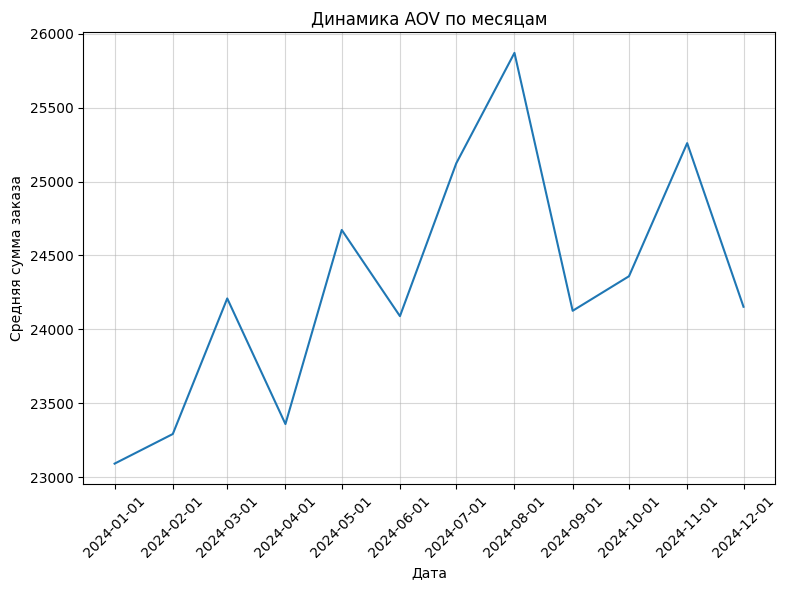

In [42]:
# построим график динамики aov
plt.figure(figsize=(8, 6))

plt.plot(aov_dynamic['order_month'], aov_dynamic['aov_month'])

ax = plt.gca()

month_dates = pd.date_range(start=start_date, end=end_date, freq='MS')
month_tick_locations = mdates.date2num(month_dates)

ax.xaxis.set_major_locator(FixedLocator(month_tick_locations))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
ax.xaxis.set_minor_locator(ticker.NullLocator())
ax.grid(alpha=0.5)
ax.tick_params(axis='x', labelrotation=45)

plt.xlabel('Дата')
plt.ylabel('Средняя сумма заказа')
plt.title('Динамика AOV по месяцам')
plt.tight_layout()
plt.show()

Средний чек заказа имеет тенденцию к росту втечение всего года. При этом наблюдаеся резкий скачек в августе с таким же резким падением до прежних значений.

### <a id="metrics_conclusion"></a> Вывод по обзору ключевых метрик

По результатам года маркетплейс показал окупаемость, при этом динамика выручки и расходов показала, что конец года был убыточным. С мая падает конверсия в покупку, средняя выручка на пользователя и "липкость" продукта - вероятно, это обусловлено притоком мало мотивированных пользователей. Несмотря на это средняя сумма заказа имеет тенденцию к росту - покупающие пользователи видят ценность и тратят большие суммы на заказы. Сильно скошенная влево гистограмма распределения суммы заказов пользователей говорит о том, что пользователей можно разделить на тех, кто совершает небольшие покупки и приносит сравнительно небольшую выручку маркетплейсу, и на пользователей, совершающих дорогостощие покупки - эта информация открывает возможности для сегментации пользователей. Анализ retention показывает резкое падение до 10 процентов на 5 месяцев после регистрации, на 9 месяц пользователи уходят из продукта - короткий лайфтайм клиентов приводит к их удорожанию в юнит-экономике.

## <a id="unit_economics"></a> Анализ юнит-экономики

### <a id="ltv_cac_roi_60days"></a> LTV, CAC и ROI с горизонтом событий 60 дней

Начнем с анализа LTV, CAC и ROI по когортам месяцев. Зададим горизонт событий в 60 дней - будем считать всю выручку от втечение 60 дней с даты регистрации пользователей когорты.

In [43]:
# рассчитаем ltv при lifetime 60 дней, cac и roi по когортам месяцев
paying_users_60DaysLTV_dynamic = pa_marketplace_orders.loc[pa_marketplace_orders['lifetime'] <= 60].groupby(
    ['user_id', 'cohort_month']).agg(
    user_revenue=('order_revenue', 'sum')
).reset_index()

cohort_revenue_60DaysLTV = paying_users_60DaysLTV_dynamic.groupby('cohort_month').agg(
    total_revenue_60DaysLTV=('user_revenue', 'sum')
).reset_index()

attr_users_dynamic = pa_marketplace_users.groupby('cohort_month').agg(
    attr_users=('user_id', 'count')
).reset_index()

cohort_60DaysLTV = pd.merge(cohort_revenue_60DaysLTV, attr_users_dynamic, on='cohort_month')
cohort_60DaysLTV['60DaysLTV'] = cohort_60DaysLTV['total_revenue_60DaysLTV'] / cohort_60DaysLTV['attr_users']

cohort_costs = pa_marketplace_campaign_costs.groupby('spend_month').agg(month_costs=('budget', 'sum')).reset_index()
cohort_cac = pd.merge(attr_users_dynamic, cohort_costs, left_on='cohort_month', right_on='spend_month')
cohort_cac['cac'] = cohort_cac['month_costs'] / cohort_cac['attr_users']

cohort_roi = pd.merge(cohort_60DaysLTV, cohort_cac, on='cohort_month')
cohort_roi['roi'] = 100 * (cohort_roi['60DaysLTV'] - cohort_roi['cac']) / cohort_roi['cac']

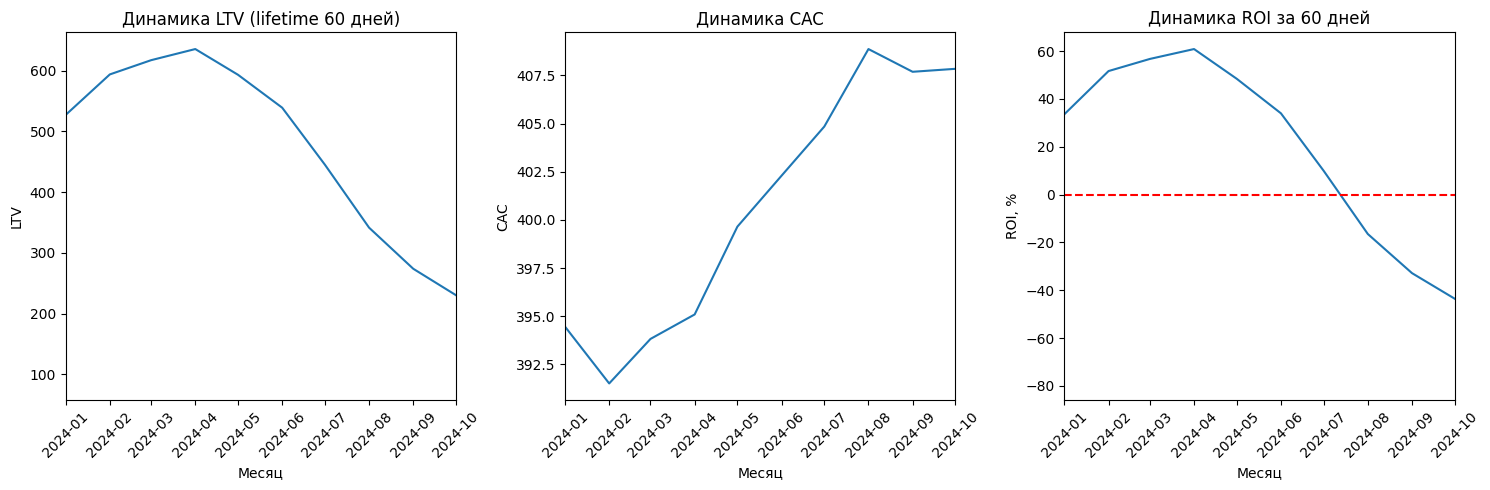

In [44]:
# построим графики динамики ltv, cac и roi
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].plot(cohort_60DaysLTV['cohort_month'], cohort_60DaysLTV['60DaysLTV'])
ax[0].set_xlim(pd.Timestamp('2024-01-01'), pd.Timestamp('2024-10-01'))
ax[0].tick_params(axis='x', labelrotation=45)
ax[0].set_xlabel('Месяц')
ax[0].set_ylabel('LTV')
ax[0].set_title('Динамика LTV (lifetime 60 дней)')

ax[1].plot(cohort_cac['cohort_month'], cohort_cac['cac'])
ax[1].set_xlim(pd.Timestamp('2024-01-01'), pd.Timestamp('2024-10-01'))
ax[1].tick_params(axis='x', labelrotation=45)
ax[1].set_xlabel('Месяц')
ax[1].set_ylabel('CAC')
ax[1].set_title('Динамика CAC')

ax[2].plot(cohort_roi['cohort_month'], cohort_roi['roi'])
ax[2].set_xlim(pd.Timestamp('2024-01-01'), pd.Timestamp('2024-10-01'))
ax[2].tick_params(axis='x', labelrotation=45)
ax[2].set_xlabel('Месяц')
ax[2].axhline(0, color='red', ls='--')
ax[2].set_ylabel('ROI, %')
ax[2].set_title('Динамика ROI за 60 дней')

plt.tight_layout()
plt.show()

Анализ метрик LTV, CAC и ROI показывает знакомую картину - 60-дневный LTV растет до апреля, послее чего падает до конца года. При этом CAC практически все время растет, хоть и не значительно. Сочетание этих факторов ведет к тому, что когорты перестают окупаться втечение двух месяцев начиная с июля.

### <a id="cohort_analysis"></a> Когортный анализ окупаемости

Проведем когортный анализ окупаемости с учетом полного ltv пользователей:

In [45]:
# рассчитаем ltv пользователей за все время наблюдений, cac, roi и payback period 
unit_ltv_month = pa_marketplace_orders.groupby(['cohort_month', 'order_month']).agg(month_revenue=('order_revenue', 'sum')).reset_index()

attr_users = pa_marketplace_users.groupby('cohort_month').agg(attr_users=('user_id', 'count')).reset_index()

unit_ltv_month = unit_ltv_month.merge(attr_users, on='cohort_month')

unit_ltv_month.sort_values(by=['cohort_month', 'order_month'], inplace=True)

unit_ltv_month['cumulative_revenue'] = unit_ltv_month.groupby('cohort_month')['month_revenue'].cumsum()

unit_ltv_month['ltv'] = unit_ltv_month['cumulative_revenue'] / unit_ltv_month['attr_users']

unit_ltv_month = unit_ltv_month.merge(costs_month, left_on='cohort_month', right_on='spend_month')

unit_ltv_month['cac'] = unit_ltv_month['budget'] / unit_ltv_month['attr_users']

unit_ltv_month['roi'] = 100 * (unit_ltv_month['ltv'] - unit_ltv_month['cac']) / unit_ltv_month['cac']

unit_ltv_month['n_period'] = (
    unit_ltv_month['order_month'].dt.to_period('M').astype('int64')
    - unit_ltv_month['cohort_month'].dt.to_period('M').astype('int64')
)

unit_ltv_month['Payback_Period'] = unit_ltv_month.apply(
  lambda row: row['n_period'] + 1 if row['ltv'] >= row['cac'] else 0, axis=1)

In [46]:
# сформируем сводную таблицу с данными для построения heatmap
roi_pivot = pd.pivot(
    unit_ltv_month,
    values='roi',
    index='cohort_month',
    columns='n_period'
)

roi_pivot.index = pd.to_datetime(roi_pivot.index).strftime('%Y-%m-%d')

payback_pivot = unit_ltv_month.pivot(
    index='cohort_month',
    columns='n_period',
    values='Payback_Period'
)
payback_pivot.index = pd.to_datetime(payback_pivot.index).strftime('%Y-%m-%d')

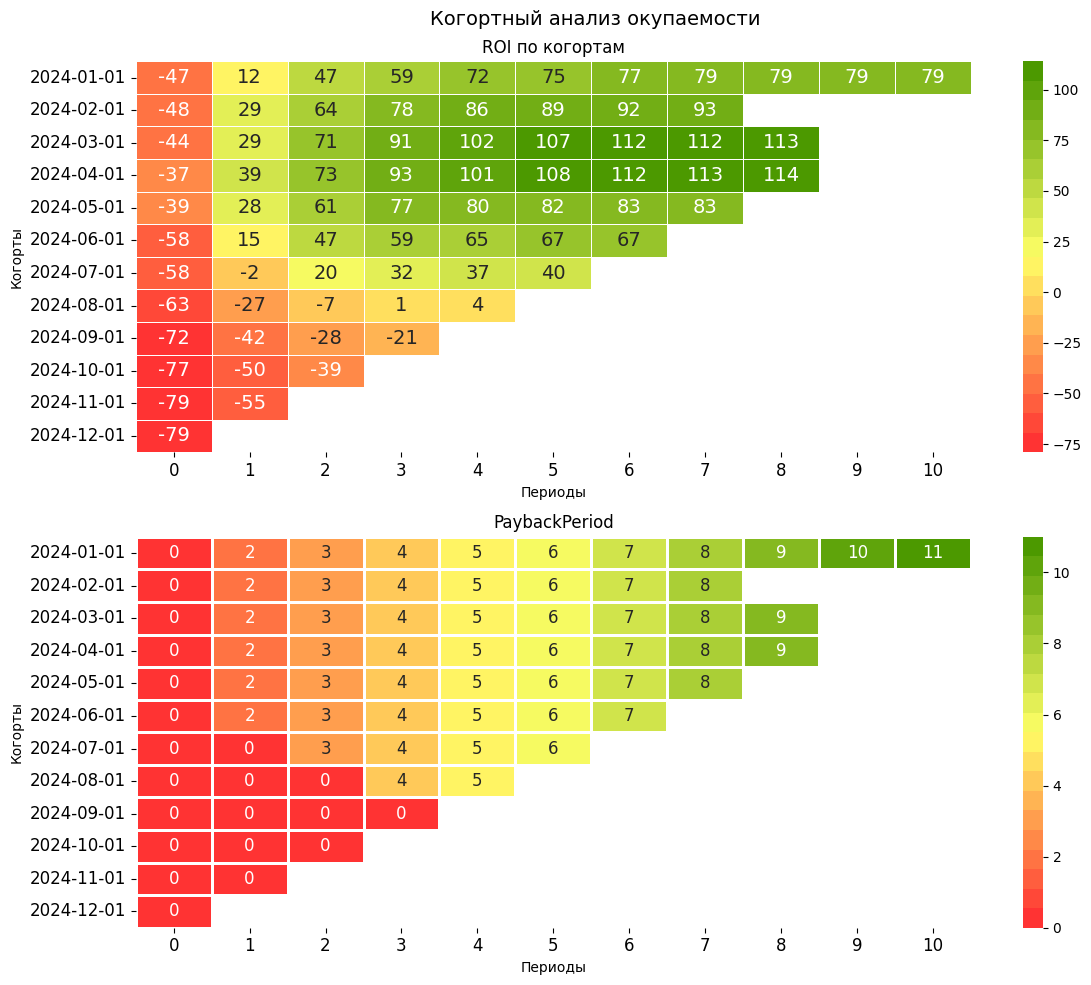

In [47]:
# построим heatmap ROI и Payback period по когортам
fig, ax = plt.subplots(2, 1, figsize=(12, 10))

cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=20) # красивые цвета heatmap

sns.heatmap(roi_pivot,
           cmap=cmap,
           annot=True,
           fmt='.0f',
           linewidth=0.5,
           annot_kws={"size": 14},
           ax=ax[0])

ax[0].set_title('ROI по когортам')
ax[0].set_xlabel('Периоды')
ax[0].set_ylabel('Когорты')
ax[0].tick_params(labelsize=12) 

sns.heatmap(payback_pivot,
          cmap=cmap,
          annot=True,
          fmt='.0f',
          linewidths=2,
          annot_kws={"size": 12},
          ax=ax[1])

ax[1].set_title('PaybackPeriod')
ax[1].set_xlabel('Периоды')
ax[1].set_ylabel('Когорты')
ax[1].tick_params(labelsize=12) 

plt.suptitle('Когортный анализ окупаемости', fontsize=14)
plt.tight_layout()
plt.show()

Самый высокий roi показывают когорты марта и апреля - значения достигают 100 % - на каждый вложенный рубль эти когорты принесли 2 рубля. Дальше roi начинает падать. В результате период окупаемости вложений увеличивается с 2 месяцев до 4 для последней когорты, для которой доступны данные втечение четырех месяцев.

### <a id="unit_economics_conclusion"></a> Вывод по анализу юнит-экономики

LTV падает с апреля, что вместе с ростом cac приводит к падению roi и увеличению периода окупаемости. Сентябрьская и октябрьская когорты могли бы окупиться втечение 2024 года, если бы имели юнит-экономику начала года, но им этого не удалось. При этом наиболее удачные когорты - мартовская и апрельская - показали ROI выше 100 процентов.

## <a id="channel_analysis"></a> Анализ в разрезе каналов привлечения

In [48]:
# Добавим в датасет с заказами данные о канале привлечения
pa_marketplace_orders = pa_marketplace_orders.merge(pa_marketplace_users[['user_id', 'acq_channel']], on='user_id')

In [49]:
# подсчитаем кол-во пользователей по каналам и средний cac
users_by_channel = pa_marketplace_users.groupby('acq_channel')['user_id'].count().reset_index()

mean_cac_channel = pa_marketplace_campaign_costs.groupby('acq_channel')['budget'].sum().reset_index()
mean_cac_channel = mean_cac_channel.merge(users_by_channel, on='acq_channel')
mean_cac_channel['cac'] = mean_cac_channel['budget'] / mean_cac_channel['user_id']

mean_cac_channel.sort_values(by='cac', inplace=True)

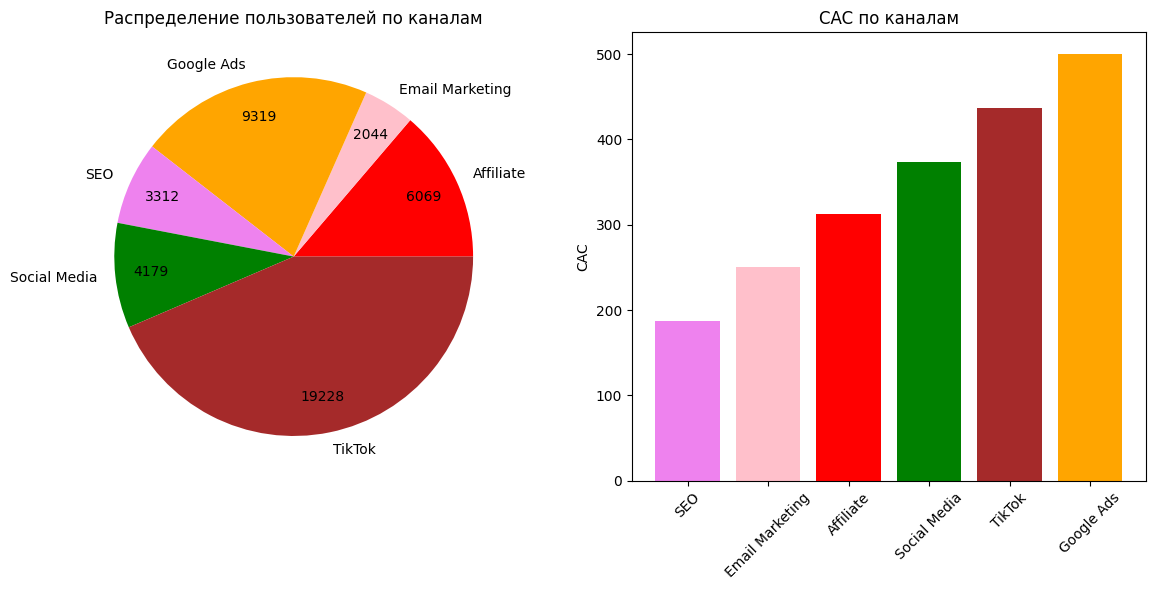

In [50]:
# построим диаграмму распределения пользователей по каналам и диаграмму среднего cac по каналам
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

channel_color_map = {
    'Affiliate': 'red',
    'Direct': 'blue',
    'Email Marketing': 'pink',
    'Google Ads': 'orange',
    'SEO': 'violet',
    'Social Media': 'green',
    'TikTok': 'brown'
}

wedges, texts, autotexts = ax[0].pie(users_by_channel['user_id'],
        labels=users_by_channel['acq_channel'],
        colors=get_colors(users_by_channel['acq_channel'].unique(), channel_color_map),          
        autopct=lambda pct: absolute_value(pct, users_by_channel['user_id'].values),
         pctdistance=0.8,
         labeldistance=1.1)

ax[0].set_title('Распределение пользователей по каналам')

ax[1].bar(mean_cac_channel['acq_channel'], mean_cac_channel['cac'], color=get_colors(mean_cac_channel['acq_channel'].unique(), channel_color_map))
ax[1].tick_params(axis='x', labelrotation=45)
ax[1].set_ylabel('CAC')
ax[1].set_title('CAC по каналам')

plt.tight_layout()
plt.show()

Больше всего пользователей привлекает TikTok, на втором месте Google Ads. Они же занимают имеют самые высокие стоимости привлечения пользователей.

___
Посмотрим на динамику привлечения пользователей по каналам

In [51]:
# посчитаем кол-во привлеченных пользователей по месяцам для разных каналов
attr_users_channel = pa_marketplace_users.groupby(['acq_channel', 'cohort_month']).agg(users_count=('user_id', 'count')).reset_index()

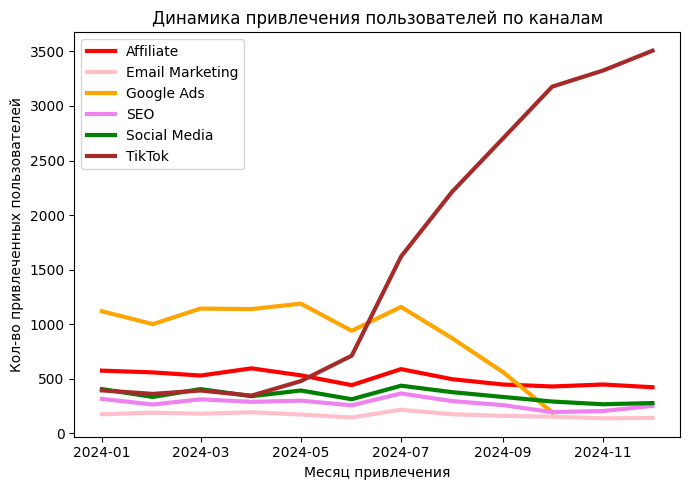

In [52]:
# построим график динамики привлечения пользователей по каналам
plt.figure(figsize=(7, 5))

for channel in attr_users_channel['acq_channel'].unique():
    plot_df = attr_users_channel.loc[attr_users_channel['acq_channel'] == channel]
    plt.plot(plot_df['cohort_month'], plot_df['users_count'], label=f'{channel}',
            color=channel_color_map[channel], lw=3)
    
plt.legend()
    
plt.xlabel('Месяц привлечения')
plt.ylabel('Кол-во привлеченных пользователей')

plt.title('Динамика привлечения пользователей по каналам')

plt.tight_layout()
plt.show()

TikTok показал резкий рост с июня - так, к концу года TikTok привлекал по 3500 пользователей, тогда как все остальные каналы имели не более 500 каждый. Такая динамика с учетом высокой стоимости привлечения объясняет падение ROI во второй половине года и выход из зоны окупаемости.
Канал Google Ads имел больше всего привлеченных пользователей до июня, где уступил TikTok и начал падать. С октября новых пользователей Google Ads не приводил - видимо, затраты на маркетинг были пересмотрены в пользу TikTok. Как было показано ранее, такой шаг не оправдал себя.
Привлечение каналов Affiliate, Social Media, SEO и Email Marketing постоянно, при этом каналы приводят сравнительно немного пользователей.

___
Проанализуем динамику CAC и LTV пользователей по каналам при Lifetime 60 дней

In [53]:
# посчитаем cac по месяцам для разных каналов
users_month_acq_channel = pa_marketplace_users.groupby(['acq_channel', 'cohort_month']).agg(users_count=('user_id', 'count')).reset_index()

cac_channel = pa_marketplace_campaign_costs[['acq_channel', 'spend_month', 'budget']].merge(
    users_month_acq_channel,
    left_on=['acq_channel', 'spend_month'],
    right_on=['acq_channel', 'cohort_month'], how='left')

cac_channel['cac'] = cac_channel['budget'] / cac_channel['users_count']

In [54]:
# посчитаем LTV по месяцам для разных каналов при lifetime 60 дней
paying_users_60DaysLTV_channel_dynamic = pa_marketplace_orders.loc[pa_marketplace_orders['lifetime'] <= 60].groupby(['user_id', 'cohort_month', 'acq_channel']).agg(user_revenue=('order_revenue', 'sum')).reset_index()

channel_cohort_revenue_60DaysLTV = paying_users_60DaysLTV_channel_dynamic.groupby(['cohort_month', 'acq_channel']).agg(
    channel_cohort_revenue_60Days=('user_revenue', 'sum')
).reset_index()

attr_users_channel_dynamic = pa_marketplace_users.groupby(['acq_channel', 'cohort_month']).agg(
    channel_attr_users=('user_id', 'count')
).reset_index()

channel_cohort_60DaysLTV = channel_cohort_revenue_60DaysLTV.merge(attr_users_channel_dynamic, on=['acq_channel', 'cohort_month'])

channel_cohort_60DaysLTV['60DaysLTV'] = channel_cohort_60DaysLTV['channel_cohort_revenue_60Days'] / channel_cohort_60DaysLTV['channel_attr_users']

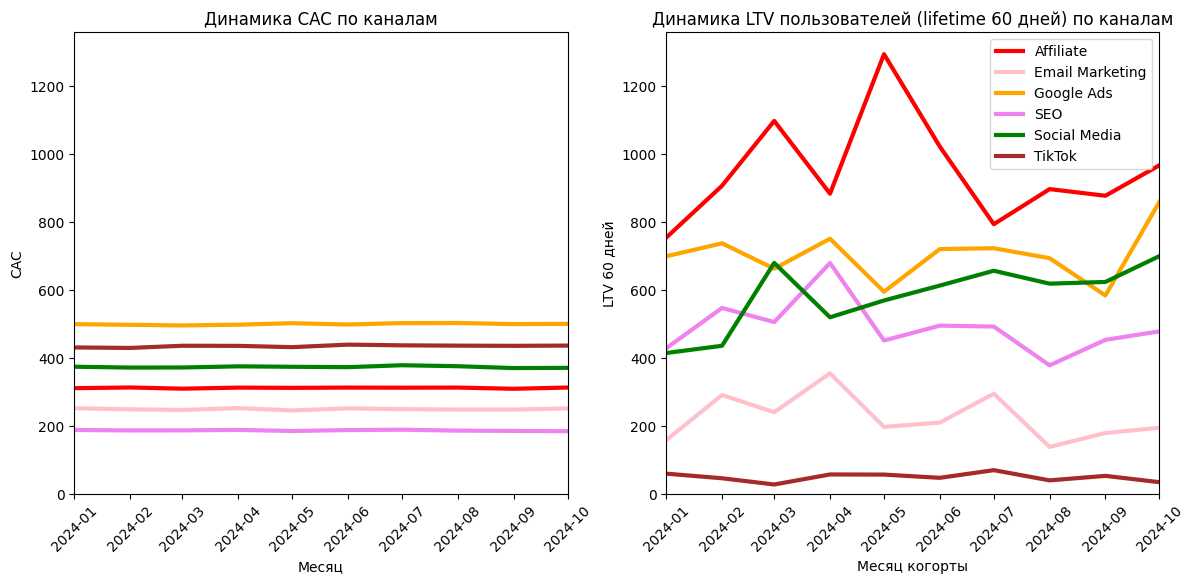

<Figure size 800x600 with 0 Axes>

In [55]:
# построим график CAC и LTV по месяцам для разных каналов
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

for channel in cac_channel['acq_channel'].unique():
    plot_data = cac_channel.loc[cac_channel['acq_channel'] == channel]
    ax[0].plot(plot_data['spend_month'], plot_data['cac'], label=f'{channel}',
            color=channel_color_map[channel], lw=3)

ax[0].set_xlabel('Месяц')
ax[0].set_ylabel('CAC')
ax[0].tick_params(axis='x', labelrotation=45)
ax[0].set_xlim(pd.Timestamp('2024-01-01'), pd.Timestamp('2024-10-01'))
ax[0].set_ylim(0, channel_cohort_60DaysLTV['60DaysLTV'].max() * 1.05)
ax[0].set_title('Динамика CAC по каналам')

plt.figure(figsize=(8, 6))

for channel in channel_cohort_60DaysLTV['acq_channel'].unique():
    plot_data = channel_cohort_60DaysLTV.loc[channel_cohort_60DaysLTV['acq_channel'] == channel]
    ax[1].plot(plot_data['cohort_month'], plot_data['60DaysLTV'], label=f'{channel}',
             lw=3, color=channel_color_map[channel])

ax[1].set_xlabel('Месяц когорты')
ax[1].set_ylabel('LTV 60 дней')
ax[1].set_xlim(pd.Timestamp('2024-01-01'), pd.Timestamp('2024-10-01'))
ax[1].set_ylim(0, channel_cohort_60DaysLTV['60DaysLTV'].max() * 1.05)
ax[1].tick_params(axis='x', labelrotation=45)
ax[1].legend()
ax[1].set_title('Динамика LTV пользователей (lifetime 60 дней) по каналам')

plt.tight_layout()
plt.show()

TikTok за все время наблюдений не окупался - при таком соотношении LTV и CAC, как у TikTok, при учете доли канала в привлечение пользователей, можно назвать этот канал основной причиной ухудшения окупаемости.<br>
Канал Google Ads, не смотря на высокий CAC, окупался втечение всего периода наблюдения. Если предположение о том, что бюджеты Google Ads были перенаправлены в TikTok, верно, можно однозначно сказать, что анализ данных показал несостоятельность этого подхода.<br>
Кроме этого, окупаются каналы SEO, SocialMedia и Affiliate. Канал Affiliate показывает самые высокие значения LTV.

___
Проведем когортный анализ окупаемости для окупающихся каналов:

In [56]:
# рассчитаем полный LTV, CAC и ROI по когортам и каналам 
ltv_cohort_channel = pa_marketplace_orders.merge(pa_marketplace_users[['user_id', 'acq_channel']])

ltv_cohort_channel = ltv_cohort_channel.groupby(['acq_channel', 'cohort_month', 'order_month']).agg(
    month_revenue=('order_revenue', 'sum')
).reset_index()

channel_attr_users = pa_marketplace_users.groupby(['acq_channel', 'cohort_month']).agg(
    attr_users=('user_id', 'count')
).reset_index()

ltv_cohort_channel = ltv_cohort_channel.merge(channel_attr_users, on=['acq_channel', 'cohort_month'])

ltv_cohort_channel.sort_values(by=['acq_channel', 'cohort_month', 'order_month'], inplace=True)

ltv_cohort_channel['cumulative_revenue'] = ltv_cohort_channel.groupby(['acq_channel', 'cohort_month'])['month_revenue'].cumsum()

ltv_cohort_channel['ltv'] = ltv_cohort_channel['cumulative_revenue'] / ltv_cohort_channel['attr_users']

ltv_cohort_channel = ltv_cohort_channel.merge(cac_channel[['acq_channel', 'cohort_month', 'cac']], on=['acq_channel', 'cohort_month'])

ltv_cohort_channel['roi'] = 100 * (ltv_cohort_channel['ltv'] - ltv_cohort_channel['cac']) / ltv_cohort_channel['cac']

ltv_cohort_channel['n_period'] = (
    ltv_cohort_channel['order_month'].dt.to_period('M').astype('int64') - 
    ltv_cohort_channel['cohort_month'].dt.to_period('M').astype('int64')
)

ltv_cohort_channel['Payback_Period'] = ltv_cohort_channel.apply(
  lambda row: row['n_period'] + 1 if row['ltv'] >= row['cac'] else 0, axis=1)

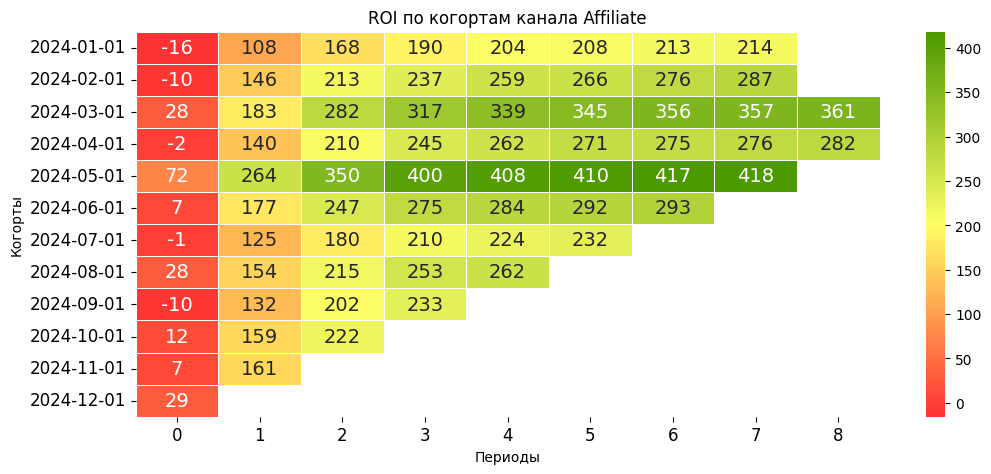

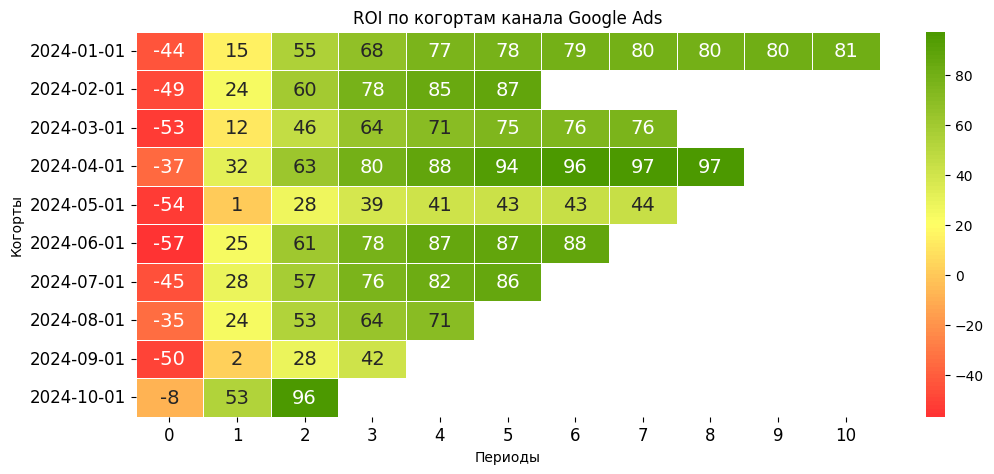

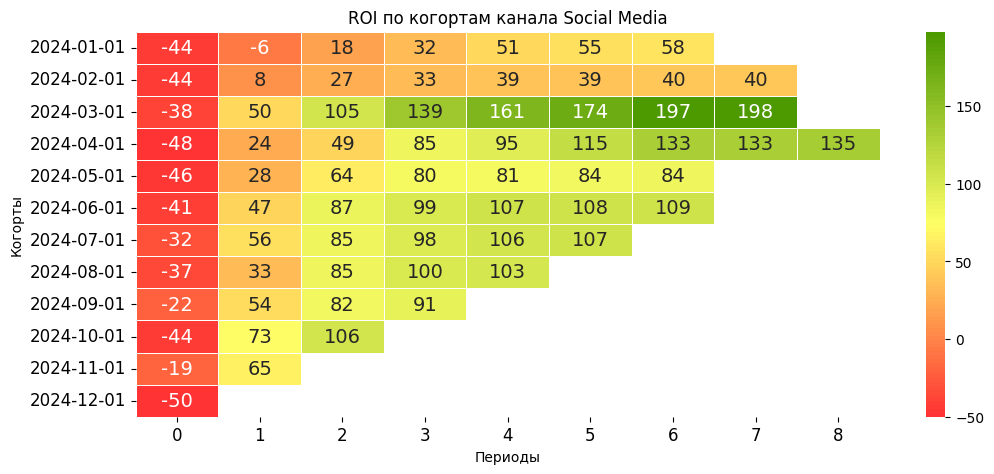

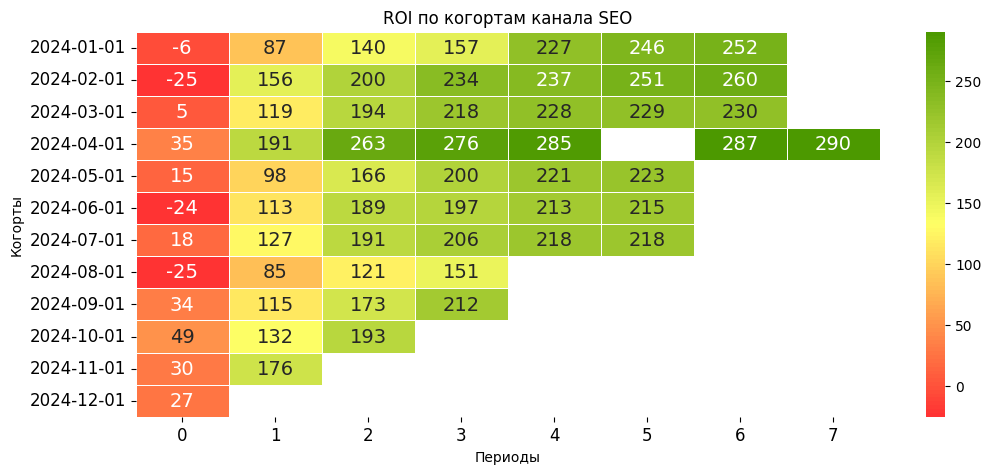

In [57]:
# построим heatmap ROI для окупающихся каналов
cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N=100) # красивые цвета heatmap

good_channels = ['Affiliate', 'Google Ads', 'Social Media', 'SEO']

for channel in good_channels:
     
    pivot_data = ltv_cohort_channel.loc[ltv_cohort_channel['acq_channel'] == channel]

    roi_pivot = pd.pivot(pivot_data,
                                values='roi',
                                index='cohort_month',
                                columns='n_period')

    roi_pivot.index = pd.to_datetime(roi_pivot.index).strftime('%Y-%m-%d')

    plt.figure(figsize=(12,5))
    sns.heatmap(roi_pivot,
               cmap=cmap,
               annot=True,
               fmt='.0f',
               linewidth=0.5,
               annot_kws={"size": 14})

    plt.title(f'ROI по когортам канала {channel}')
    plt.xlabel('Периоды')
    plt.ylabel('Когорты')
    plt.yticks(rotation=0)
    plt.tick_params(labelsize=12)
    
plt.show()

Для половины когорт канал Affiliate окупается уже на первом месяце. Максимальный ROI превышает 400% для майской когорты. При этом на 5-ый месяц ROI практически перестает расти, обеспечивая в среднем больше 250 % чистой прибыли. Канал имеет мощный потенциал для роста за счет перераспределения маркетинговых затрат.<br>
Когорты канала Google Ads окупается со второго месяца после регистрации. На 5-ый месяц после регистрации ROI в среднем 80%. Есть просадка в когорте мая - до 40%. С учетом объема привлеченных пользователей канал формирует значимый объем чистой прибыли.<br>
Канал Social Media окупаетмся со второго месяца после регистрации. На 5-ый месяц ROI в среднем 100%, при этом когорты сильно неоднородные - первые два месяца года последний ROI около 50%, скачек в марте до 200 % с последующим спадом до 100% для следующих когорт. Канал имеет потенциал к развитию.<br>
Канал SEO по значениям ROI занимает второе место. Канал начинает окупаться практически с месяца регистрации, достигая максимального ROI для апрельской когорты в 290%. Средний ROI на 5-ый месяц около 230-240%. Канал имеет высокий потенциал развития за счет перераспределения маркетинговых затрат.

### <a id="channel_analysis_conclusion"></a> Вывод по  анализу в разрезе каналов привлечения

- Больше всего пользователей привлекает TikTok, на втором месте Google Ads. Они же занимают имеют самые высокие стоимости привлечения пользователей. Динамика привлечения в TikTok показала резкий рост с июня - так, к концу года TikTok привлекал по 3500 пользователей, тогда как все остальные каналы имели не более 500 каждый. Канал Google Ads имел больше всего привлеченных пользователей до июня, где уступил TikTok и начал падать. Привлечение каналов Affiliate, Social Media, SEO и Email Marketing постоянно, каналы приводят сравнительно немного пользователей.<br>
- TikTok за все время наблюдений не окупался - при таком соотношении LTV и CAC, как у TikTok, при учете доли канала в привлечение пользователей, можно назвать этот канал основной причиной ухудшения окупаемости. Канал Google Ads, не смотря на высокий CAC, окупался втечение всего периода наблюдения. Если предположение о том, что бюджеты Google Ads были перенаправлены в TikTok, верно, можно однозначно сказать, что анализ данных показал несостоятельность этого подхода. Кроме этого, окупаются каналы SEO, SocialMedia и Affiliate. Канал Affiliate показывает самые высокие значения LTV.<br>
- Для половины когорт канал Affiliate окупается уже на первом месяце. Максимальный ROI превышает 400% и в среднем больше 250 %. Когорты канала Google Ads окупается со второго месяца после регистрации, средний ROI под конец 80%. За счет доли пользователей канал формирует значимый объем чистой прибыли. Канал Social Media окупаетмся со второго ROI 100 %, при этом когорты сильно неоднородные. Канал SEO начинает окупаться практически с месяца регистрации, достигая максимального ROI в 290% при среднем ROI ~ 230-240%.<br>
- Наиболее перспективные каналы - Affiliate и SEO. Перераспределение маркетинговых затрат на эти каналы может привести к росту чистой прибыли. Канал TikTok имеет крайне высокую стоимость привлечения и за весь период не окупался - необходимо сокращать затраты на этот канал, либо удешевлять стоимость привлечения через этот канал от площадки.<br>
<br>

## <a id="funnel"></a> Анализ воронки

Перейдем к анализу воронки:

In [58]:
# посчитаем классическую воронку и step-by-step воронку для всех пользователей
funnel_steps = ['page_view', 'product_view', 'add_to_cart', 'checkout_start', 'checkout_complete']

funnel_events = pa_marketplace_events.loc[pa_marketplace_events['event_type'].isin(funnel_steps)]

funnel_users_count = funnel_events.groupby('event_type')['user_id'].nunique().reset_index()

funnel_users_count = funnel_users_count.sort_values(by='user_id', ascending=False)

order_users = pd.DataFrame({'user_id': [pa_marketplace_orders['user_id'].nunique()],
                            'event_type': 'order_payment'})

funnel_users_count = pd.concat([funnel_users_count, order_users])

funnel_users_count['conversion_from_first_%'] = (funnel_users_count['user_id'] / funnel_users_count['user_id'].iloc[0] * 100).round(1)
funnel_users_count['conversion_from_previous_%'] = (funnel_users_count['user_id'] / funnel_users_count['user_id'].shift(1) * 100).round(1)

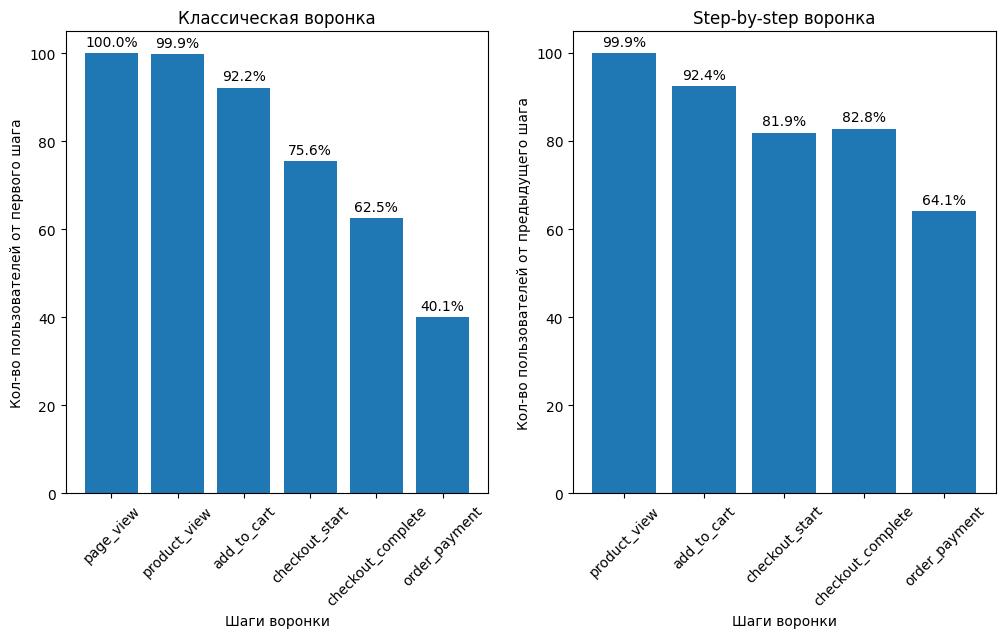

In [59]:
# построим столбчатые диаграммы для классической и step-by-step воронки
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

bars0 = ax[0].bar(funnel_users_count['event_type'], funnel_users_count['conversion_from_first_%'])

for bar in bars0:
    height = bar.get_height()
    ax[0].annotate(f'{height:.1f}%',
                   xy=(bar.get_x() + bar.get_width() / 2, height),
                   xytext=(0, 3),
                   textcoords="offset points",
                   ha='center', va='bottom',
                   fontsize=10)

ax[0].set_xlabel('Шаги воронки')
ax[0].set_ylabel('Кол-во пользователей от первого шага')
ax[0].set_title('Классическая воронка')
ax[0].tick_params(axis='x', labelrotation=45) 

bars1 = ax[1].bar(funnel_users_count['event_type'], funnel_users_count['conversion_from_previous_%'])

for bar in bars1:
    height = bar.get_height()
    ax[1].annotate(f'{height:.1f}%',
                   xy=(bar.get_x() + bar.get_width() / 2, height),
                   xytext=(0, 3),
                   textcoords="offset points",
                   ha='center', va='bottom',
                   fontsize=10)

ax[1].set_xlabel('Шаги воронки')
ax[1].set_ylabel('Кол-во пользователей от предыдущего шага')
ax[1].set_title('Step-by-step воронка')
ax[1].tick_params(axis='x', labelrotation=45)

plt.show()

До покупки доходит 40% от всех пользователей, зашедших на сайт или в приложение. Наиболее значимые просадки, проявляются на этапах начала и окончания оформления заказа и на этапе оплаты. Каждый третий пользователь, оформивший заказ, не оплачивает его. Увелчение доли оплаты заказов приведет к увеличению прибыли. Возможно, следует проанализировать форму оплаты заказа на предмет сложностей для пользователей.

## <a id="os_analysis"></a> Анализ в разрезе устройств пользователей

Проанализируем пользователей по операционным системам

In [60]:
# Посчитаем кол-во пользователей с определенной OS и выручку по группам OS 
os_users_count = pa_marketplace_events.groupby('os')['user_id'].nunique().reset_index()

os_revenue_df = pa_marketplace_orders.merge(pa_marketplace_events[['user_id', 'os']].drop_duplicates(), on='user_id')

os_revenue_dynamic = os_revenue_df.groupby(['order_month', 'os']).agg(
    total_revenue=('order_revenue', 'sum')
).reset_index()

os_revenue = os_revenue_df.groupby('os').agg(total_revenue=('order_revenue', 'sum')).reset_index()

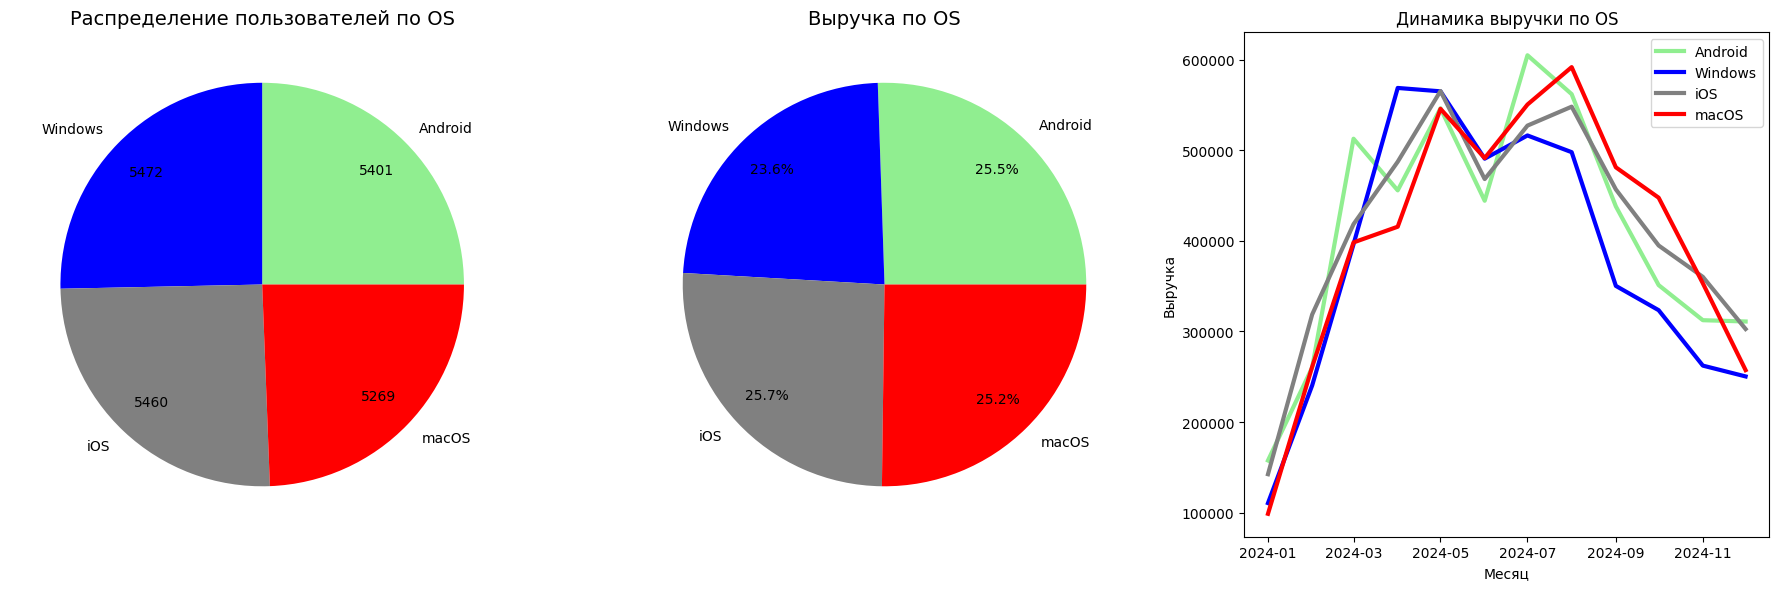

In [61]:
# построим диаграмму распределения пользователей по OS, диаграмму распределения выручки по OS и график динамики выручки
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

os_colors = {
    'Windows': 'blue',
    'Android': 'lightgreen',
    'iOS': 'grey',
    'macOS': 'red'
}

ax[0].pie(os_users_count['user_id'],
        labels=os_users_count['os'],          
        autopct=lambda pct: absolute_value(pct, os_users_count['user_id'].values),
         pctdistance=0.8,
         labeldistance=1.1,
         colors=get_colors(os_users_count['os'].unique(), os_colors))

ax[0].set_title('Распределение пользователей по OS', fontsize=14)

ax[1].pie(os_revenue['total_revenue'],
        labels=os_revenue['os'],          
        autopct='%1.1f%%',
         pctdistance=0.8,
         labeldistance=1.1,
         colors=get_colors(os_revenue['os'].unique(), os_colors))

ax[1].set_title('Выручка по OS', fontsize=14)

for os in os_revenue_dynamic['os'].unique():
    plot_df = os_revenue_dynamic.loc[os_revenue_dynamic['os'] == os]
    ax[2].plot(plot_df['order_month'], plot_df['total_revenue'], lw=3, color=os_colors[os], label=f'{os}')
    
ax[2].legend()
ax[2].set_xlabel('Месяц')
ax[2].set_ylabel('Выручка')
ax[2].set_title('Динамика выручки по OS')
plt.tight_layout()
plt.show()

Анализ пользователей по OS не выявил значимых отличий: пользователи разделены примерно поровну между операционными системами; выручка, аккумулированная по пренадлежности пользователя к OS, так же распределена равномерно. Динамика выручки схожа с динамикой общей выручки с небольшими изменениями. 

## <a id="goods_category"></a> Анализ в разрезе категорий товаров

### <a id="category_cr"></a> Конверсия в заказ по категориям товаров

In [62]:
category_df = pa_marketplace_orders.groupby('category_name').agg(
    total_rev=('order_revenue', 'sum'),
    total_quantity=('quantity', 'sum'),
    orders_count=('order_id', 'count')
).reset_index()

category_df['avg_price'] = category_df['total_rev'] / category_df['total_quantity']

product_categories = pa_marketplace_orders[['category_name', 'product_name']].drop_duplicates()

pa_marketplace_events = pa_marketplace_events.merge(product_categories, on='product_name', how='left')

add_to_cart_df = pa_marketplace_events.loc[pa_marketplace_events['event_type'].isin(['add_to_cart'])].groupby(['event_type', 'category_name'])['event_id'].count().reset_index()

add_to_cart_df.rename(columns={'event_id': 'add_to_cart_events'}, inplace=True)

category_df = category_df.merge(add_to_cart_df[['category_name', 'add_to_cart_events']], on='category_name')

category_df['cr'] = 100 * category_df['orders_count'] / category_df['add_to_cart_events']

category_df.sort_values(by='cr', inplace=True)

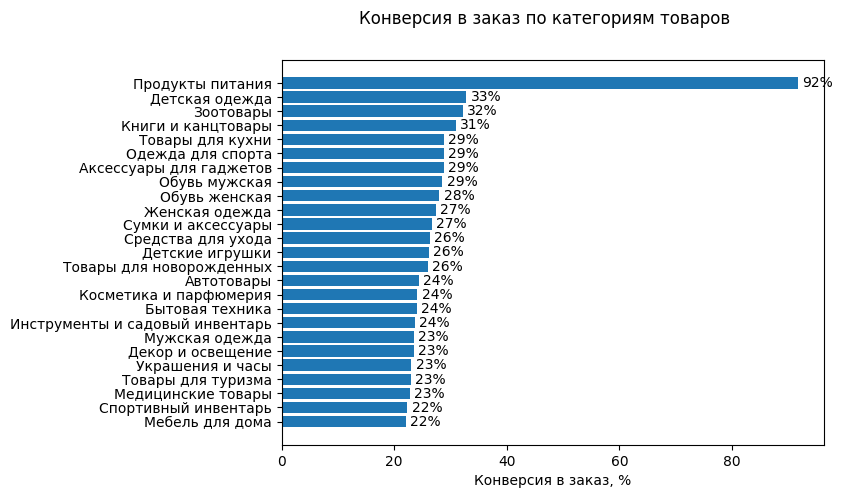

In [63]:
# построим линейную диаграмму конверсии в заказ для категорий товаров
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.barh(
    width=category_df['cr'],
    y=category_df['category_name']
)
ax.bar_label(bars,
             fmt="%.0f%%",
             padding=3)

ax.set_xlabel("Конверсия в заказ, %")

fig.suptitle("Конверсия в заказ по категориям товаров")

plt.show()

Категория "Продукты питания" лидирует по CR с большим отрывом - конверсия 92 %.
Остальные категории по интервалам CR:
1) CR от 30 до 35 %: Детская одежда, зоотовары, книги и канцтовары
2) CR от 25 до 30 %: Товары для кухни, одежда для спорта, аксессуары для гаджетов, обувь мужская и женская, сумки и аксессуары, средства для ухода, детские игрушки, товары дял новорожденных
3) CR от 20 до 25 %: Автотовары, косметика и парфюмерия, бытовая техника, инструменты и садовый инвентарь, мужская одежда, декор и осведение, украшения и часы, товары для туризма, медицинские товары, спортивный инвентарь, мебель для дома

### <a id="category_clustering"></a> Кластеризация категорий товаров

Проведем кластеризацию категорий товаров на основе общего кол-ва купленных товаров, средней цены товара в категории и среднего CR в покупку.

In [64]:
# сформируем вспомогательный датасет для кластеризации
category_clastering = category_df[['category_name', 'total_quantity', 'avg_price', 'cr']].set_index('category_name')

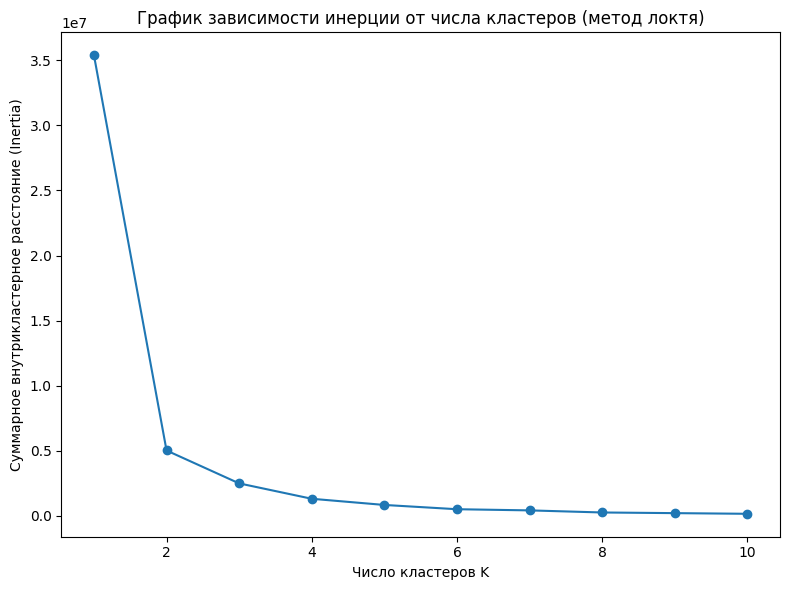

In [65]:
# посчитаем инерцию для числа кластеров от 1 до 10 и построим график для определения оптимального кол-ва кластеров
plt.figure(figsize=(8, 6))

inertia_list = []

n_min = 1
n_max = 10

num_clusters_list = range(n_min, n_max + 1)

for i in num_clusters_list:
    kmeans = KMeans(i)
    kmeans.fit(category_clastering)
    inertia_list.append(kmeans.inertia_)
    
plt.plot(num_clusters_list, inertia_list, marker='o')
plt.xlabel('Число кластеров K')
plt.ylabel('Суммарное внутрикластерное расстояние (Inertia)')
plt.title('График зависимости инерции от числа кластеров (метод локтя)')
plt.tight_layout()
plt.show()

В качестве оптимального кол-ва кластеров возьмем 3.

In [66]:
# обучим модель методом kmeans на данных о ресторанах для четырех кластеров
kmeans = KMeans(3)
kmeans.fit(category_clastering)

# определим центры кластров
centroids_df = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=category_clastering.columns
).reset_index()

In [67]:
# добавим столбец для вывода легенды на график
centroids_df['cluster_description'] = centroids_df.apply(
    lambda row: f"Куп. товаров: {row['total_quantity']:.0f} | ср. цена: {row['avg_price']:.0f} | CR: {row['cr']:.0f}", 
    axis=1)

In [68]:
# выведем центры кластеров ресторанов
centroids_df.round(1)

,index,total_quantity,avg_price,cr,cluster_description
0,0,2255.0,293.1,26.6,Куп. товаров: 2255 | ср. цена: 293 | CR: 27
1,1,7833.0,74.0,91.7,Куп. товаров: 7833 | ср. цена: 74 | CR: 92
2,2,1963.3,1249.2,23.0,Куп. товаров: 1963 | ср. цена: 1249 | CR: 23


In [69]:
# добавим в датасет category_clastering столбец с оригинальным номером кластера и добавим столбец с номером кластера после сортировки 
category_clastering['index'] = kmeans.predict(category_clastering)
category_clastering = category_clastering.merge(centroids_df[['index', 'cluster_description']], on='index')

In [70]:
category_colors = {0: 'blue', 1: 'green', 2: 'red'}

colors = centroids_df['index'].map(category_colors).tolist()

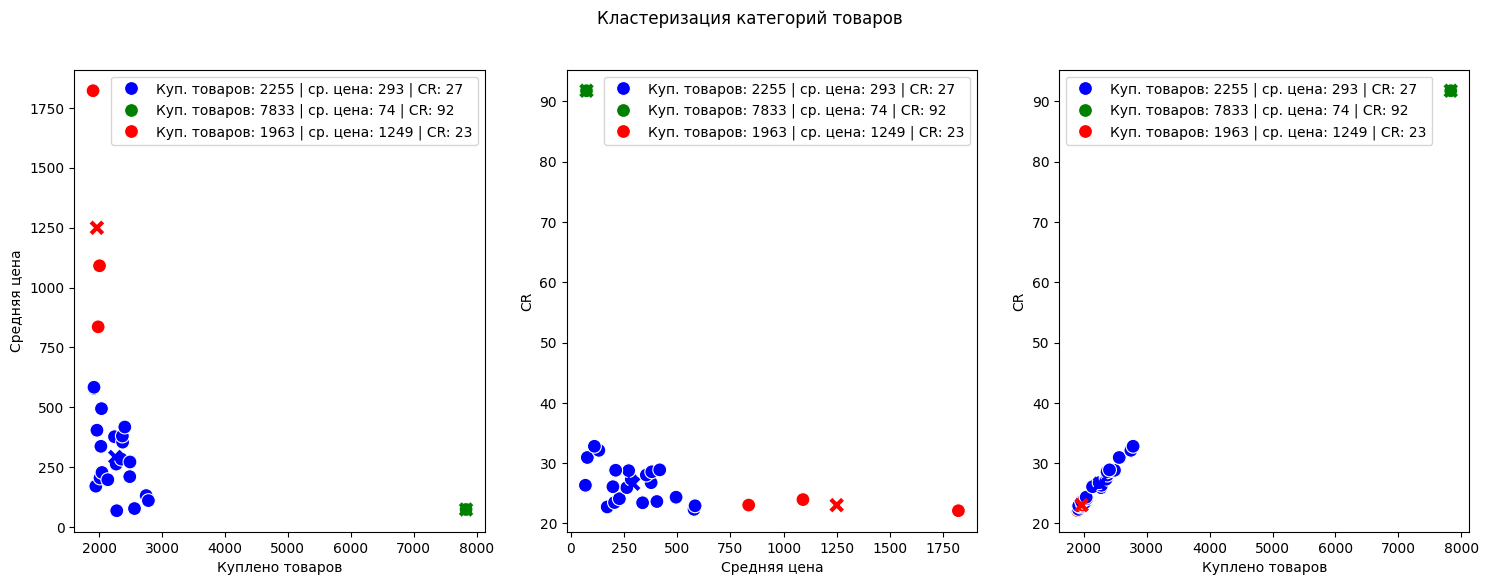

In [71]:
#построим диаграммы рассеяния 
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

sns.scatterplot(data=category_clastering,
               x='total_quantity',
               y='avg_price',
               ax=ax[0],
               hue='index',
               palette=category_colors,
               s=100,
               legend=True,
               )

handles, labels = ax[0].get_legend_handles_labels()
new_labels = centroids_df['cluster_description'].tolist() 
ax[0].legend(handles=handles, labels=new_labels)

ax[0].scatter(centroids_df['total_quantity'], centroids_df['avg_price'],
              marker='x', s=70, lw=3, c=colors)
ax[0].set_xlabel('Куплено товаров')
ax[0].set_ylabel('Средняя цена')

sns.scatterplot(data=category_clastering,
               x='avg_price',
               y='cr',
               ax=ax[1],
               hue='index',
               palette=category_colors,
               s=100,
               legend=True)

handles, labels = ax[1].get_legend_handles_labels()
new_labels = centroids_df['cluster_description'].tolist() 
ax[1].legend(handles=handles, labels=new_labels)


ax[1].scatter(centroids_df['avg_price'], centroids_df['cr'],
              marker='x', s=70, lw=3, c=colors)
ax[1].set_xlabel('Средняя цена')
ax[1].set_ylabel('CR')

sns.scatterplot(data=category_clastering,
               x='total_quantity',
               y='cr',
               ax=ax[2],
               hue='index',
               palette=category_colors,
               s=100,
               legend=True)

handles, labels = ax[2].get_legend_handles_labels()
new_labels = centroids_df['cluster_description'].tolist() 
ax[2].legend(handles=handles, labels=new_labels)


ax[2].scatter(centroids_df['total_quantity'], centroids_df['cr'],
              marker='x', s=70, lw=3, c=colors)
ax[2].set_xlabel('Куплено товаров')
ax[2].set_ylabel('CR')

plt.suptitle('Кластеризация категорий товаров')
plt.show()

Выделено 3 кластера категорий товаров:
1) c высокой ценой товаров (средняя 1250) и наиболее низким CR - 21%
2) со средней стоимостью товара 293 и CR 24%
3) со стоимостью товара 74 и CR 82% - в последний кластер вошла только одна категория "Продукты питания"

Конверсия в пропорциональна кол-ву купленных товаров. При этом снижение средней цены ведет к небольшому увеличению CR. Эту зависимость можно использовать и в обратном направлении - значительное увеличение средней стоимости товара в категории за счет расширения ассортимента или его пересмотра приводит к небольшому уменьшению конверсии на 4%. Такой вывод может быть полезен для продавцов на маркетплейсах.

## <a id="rfm_segmentation"></a> RFM-сегментация пользователей

Проведем RFM-сегментацию пользователей. Будем иметь ввиду, что признак частоты покупок уже определен для пользователей в столбце `byuer_segment`.

In [72]:
pa_marketplace_events['event_recency'] = pd.to_datetime('2025-01-01') - pa_marketplace_events['event_date']
pa_marketplace_events = pa_marketplace_events.merge(pa_marketplace_users[['user_id', 'buyer_segment']], on='user_id')

In [73]:
# сгруппируем заказы по пользователям и посчитаем давность, частоту покупок и сумму трат пользователей 
users_rfm = pa_marketplace_events.groupby('user_id').agg(
    recency=('event_recency', lambda x: x.min().days),
    frequency=('buyer_segment', 'first'),
).reset_index()

In [74]:
# посчитаем суммарную выручку для каждого пользователя и объединим с датафреймом users_rfm
monetary = pa_marketplace_orders.groupby('user_id').agg(monetary_value=('order_revenue', 'sum')).reset_index()

users_rfm = users_rfm.merge(monetary, on='user_id', how='outer')

In [75]:
# заполним пустые значения суммарной выручки для пользователей нулями
users_rfm['monetary_value'] = users_rfm['monetary_value'].fillna(0)
# удалим пропуски в столбце frequency
users_rfm = users_rfm.dropna(subset=['frequency'])

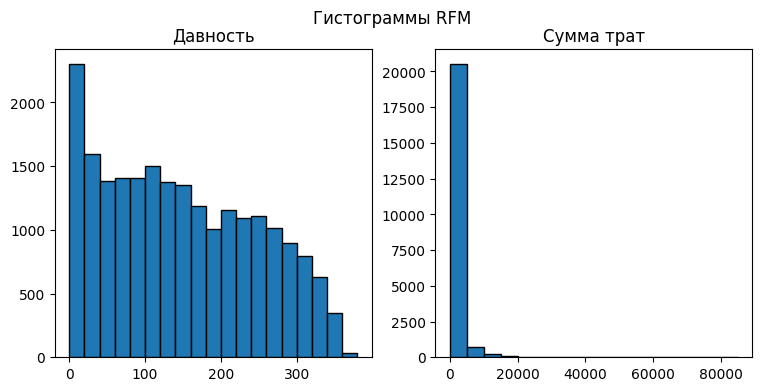

In [76]:
# построим гистограммы для давности, суммы трат
fig, ax = plt.subplots(1, 2, figsize=(9, 4))

rfm_cols = ['recency', 'monetary_value']
col_names = ['Давность', 'Сумма трат']
bin_widths = [20, 5000]

for i, (col, col_name, bin_width) in enumerate(zip(rfm_cols, col_names, bin_widths)):
    ax[i].hist(users_rfm[col], bins=bin_edge(users_rfm[col].min(), users_rfm[col].max(), bin_width), edgecolor='black')
    ax[i].set_title(col_name)
    
plt.suptitle('Гистограммы RFM')
plt.show()

- Количество пользователей по давности падает медленно падает, поэтому разобьем клиентов на три группы<br>
- Распределение суммы трат сильно скошено влево. Причиной этому является то, что в распределении учтены пользователи, не совершавшие покупок (сумма покупок равна нулю). Разобьем пользователей на 3 группы - 1 группа не совершала покупок, вторая группа совершала покупки на суммы до 20 тысяч - средний покупатель, 3 группа совершает покупки более 20 тысяч - vip покупатель.

In [77]:
# зададим вспомогательную функцию для ранжирования пользователей по частоте покупок
def frequency_segmentation(row):
    if row == 'one_time':
        return 1
    elif row == 'rare':
        return 2
    elif row == 'medium':
        return 3
    elif row == 'regular':
        return 4

In [78]:
# определим rfm сегменты пользователей
users_rfm['r'] = pd.cut(users_rfm['recency'], bins=3, labels=[3, 2, 1])
users_rfm['f'] = users_rfm['frequency'].apply(frequency_segmentation)
users_rfm['m'] = pd.cut(users_rfm['monetary_value'], bins=[0, 0.1, 20000, 1000000], include_lowest=True, labels=[1, 2, 3])

users_rfm[['r', 'f', 'm']] = users_rfm[['r', 'f', 'm']].astype('str')
users_rfm['rfm_group'] = users_rfm['r'] + users_rfm['f'] + users_rfm['m']

In [79]:
# посчитаем кол-во пользователей в rfm-сегментах
rfm_segments = users_rfm.groupby(['rfm_group', 'r', 'f', 'm']).agg(users=('user_id','count')).reset_index().sort_values(by='users')
#отсортируем сегменты по кол-ву пользователей по убыванию и посчитаем кумулятивную сумму пользователей по убыванию кол-ва пользователей в сегментах
rfm_segments = rfm_segments.sort_values(by='users', ascending=False)

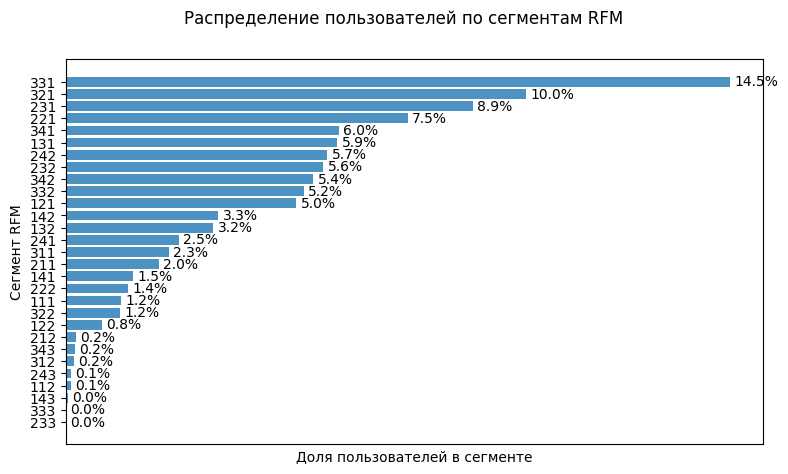

In [80]:
# построим диаграмму распределения пользователей по RFM-сегментам
fig, ax = plt.subplots(figsize=(9, 5))

rfm_plot = rfm_segments.sort_values(by='users')
rfm_plot['users'] = 100 * rfm_plot['users'] / rfm_plot['users'].sum()

bars = ax.barh(rfm_plot['rfm_group'], rfm_plot['users'], zorder=2, alpha=0.8)

ax.bar_label(bars,
             fmt="%.1f%%",
             padding=3)

ax.set_ylabel('Сегмент RFM')
ax.set_xlabel('Доля пользователей в сегменте')

ax.set_xticks(ticks=[])
ax.grid(axis='x', alpha=0.5, zorder=0)

plt.suptitle('Распределение пользователей по сегментам RFM')

plt.show()

In [81]:
vip_users_share = round(100 * rfm_segments.loc[(rfm_segments['r'].isin(['2', '3'])) & (rfm_segments['f'].isin(['3', '4'])) & (rfm_segments['m'].isin(['3']))]['users'].sum() / rfm_segments['users'].sum(), 1)
mid_users_share = round(100 * rfm_segments.loc[(rfm_segments['r'].isin(['2', '3'])) & (rfm_segments['f'].isin(['3', '4'])) & (rfm_segments['m'] == '2')]['users'].sum() / rfm_segments['users'].sum(), 1)
low_users_share = round(100 * rfm_segments.loc[(rfm_segments['r'].isin(['2', '3'])) & (rfm_segments['f'].isin(['2'])) & (rfm_segments['m'] == '2')]['users'].sum() / rfm_segments['users'].sum(), 1)
lost_active_users_share = round(100 * rfm_segments.loc[(rfm_segments['r'].isin(['1'])) & (rfm_segments['f'].isin(['2', '3', '4'])) & (rfm_segments['m'].isin(['2', '3']))]['users'].sum() / rfm_segments['users'].sum(), 1)
non_paying_users_share = round(100 * rfm_segments.loc[rfm_segments['m'] == '1']['users'].sum() / rfm_segments['users'].sum(), 1)

print(f'Доля активных пользователей, совершающих частые покупки товаров с высокими ценами = {vip_users_share} %.')
print(f'Доля активных пользователей, совершающих покупки со средней частотой и приносящих среднюю выручку маркетплейсу = {mid_users_share} %.')
print(f'Доля активных пользователей, совершающих редкие покупки и приносящих среднюю выручку маркетплейсу = {low_users_share} %.')
print(f'Доля активных ушедших пользователей = {lost_active_users_share} %.')
print(f'Доля пользователей, не совершивших ни одной покупки = {non_paying_users_share} %.')

Доля активных пользователей, совершающих частые покупки товаров с высокими ценами = 0.3 %.
Доля активных пользователей, совершающих покупки со средней частотой и приносящих среднюю выручку маркетплейсу = 21.9 %.
Доля активных пользователей, совершающих редкие покупки и приносящих среднюю выручку маркетплейсу = 2.5 %.
Доля активных ушедших пользователей = 7.4 %.
Доля пользователей, не совершивших ни одной покупки = 67.3 %.


### <a id="rfm_segmentation_conclusion"></a> Вывод по RFM-сегментации пользователей

- 67% пользователей не совершали покупок. Для этих пользователей необходимо предусмотреть меры по стимулированию первой покупки.<br>
- Самые "лучшие" пользователи для продукта - пользователи, совершающие частые покупки и приносящие высокую выручку - составляют 0.3 % от всех пользователей. Необходимо предложить специальные условия таким пользователям для их удержания в продукте.<br>
- Пользователи, совершающие покупки средней частоты и приносящие среднюю выручку, составляют 22 %. Это основная группа пользователей, генерирующая прибыль  - "средний класс" нашего продукта. Необходимо увеличивать их вовлеченность и удерживать их за счет программ лояльности.
- В прошлом активные пользователи, которые давно не совершали покупок, составляют 7% от всех пользователей. Пользователей этой категории нужно возвращать в продукт: напомнить о продукте, рассказать об изменениях, привлечь спецпредложением. Также полезно знать их мнение - почему они ушли - эта информация поможет уменьшить отток пользователей в будущем.

## <a id="ab_test_tiktok"></a> Эксперимент - Бонус на первую покупку для пользователей TikTok

На основе проведенного анализа команда продукта решила влиять на конверсию при помощи финансовых стимуляций. Дизайн эксперимента предоставлен аналитиком команды.

### Описание эксперимента

- **Бизнес-контекст:** Команда продукта запускает эксперимент, направленный на повышение конверсии среди пользователей, привлечённых через канал TikTok. Для стимулирования первой покупки пользователям будет предоставлен бонус на первую покупку.
- **Цель:** Проверить, влияет ли предоставление бонуса на первую покупку на конверсию и выручку среди пользователей TikTok.
- **Гипотеза:** Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку

___
**Формат эксперимента**
- Тип эксперимента: Сплит-роллинг (rolling split)
- Канал: Только пользователи, пришедшие с TikTok
- Группы:
    - Контрольная (A): пользователи TikTok без бонуса
    - Тестовая (B): пользователи TikTok с бонусом на первую покупку
- Распределение: Равномерное распределение новых пользователей TikTok между группами по дате регистрации
- Период проведения: 3 недели (фиксировано)

___
**Ключевые метрики**
- Основная метрика: конверсия в первую покупку — доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку
- Цель: увеличить конверсию с помощью бонуса
- Критерий успеха: статистически значимый рост конверсии в тестовой группе

**Вспомогательные метрики**
- ARPU (средняя выручка на пользователя TikTok)
- ARPPU (средняя выручка на покупателя TikTok)
- AOV (средний чек TikTok)

**Барьерная метрика**
- Общая выручка от пользователей TikTok

___
**Размеры групп и запуск**
- Целевая аудитория: только пользователи TikTok
- Размеры групп: определяются по фактическому трафику TikTok за период эксперимента
- Комментарий: запуск без предварительного расчёта мощности и MDE из-за срочности задачи

### Описание данных эксперимента

- **Events AB** - данные о событиях пользователей, участвующих в эксперименте
- **Orders AB** - данные о заказах пользователей, участвующих в эксперименте
- **Users AB** - данные о пользователях, участвующих в эксперимента

Таблицы `Events AB`, `Orders AB` и `Users AB` повторяют структуру таблиц исторических данных
___
- **Split users AB** - данные сплита пользователей

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `user_id`     | Идентификатор пользователя.                                              |
| `group`       | Группа, в которую попал клиент.                                          |

### Первичный анализ данных эксперимента

In [84]:
# загрузим данные ab-теста
pa_marketplace_events_AB = pd.read_csv('datasets/pa_marketplace_events_AB.csv',
                                      parse_dates=['event_date', 'event_week', 'event_month'])
pa_marketplace_orders_AB = pd.read_csv('datasets/pa_marketplace_orders_AB.csv',
                                      parse_dates=['order_date', 'order_week', 'order_month'])
pa_marketplace_users_AB = pd.read_csv('datasets/pa_marketplace_users_AB.csv',
                                     parse_dates=['registration_date', 'cohort_week', 'cohort_month'])
pa_marketplace_AB_split_users = pd.read_csv('datasets/pa_marketplace_AB_split_users.csv')

In [85]:
# проведем первичный анализ датасета pa_marketplace_events_AB
init_analysis(pa_marketplace_events_AB, 'pa_marketplace_events_AB')

Выведем первые пять строк датасета pa_marketplace_events_AB:


,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01 15:23:56,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01 15:24:01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01 15:24:10,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01 15:25:10,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01 15:25:46,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01




Выведем общую информацию о датасете pa_marketplace_events_AB:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 831231 entries, 0 to 831230
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   event_id      831231 non-null  int64         
 1   user_id       831231 non-null  int64         
 2   event_date    831231 non-null  datetime64[ns]
 3   event_type    831231 non-null  object        
 4   os            831231 non-null  object        
 5   device        831231 non-null  object        
 6   product_name  409054 non-null  object        
 7   event_week    831231 non-null  datetime64[ns]
 8   event_month   831231 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 57.1+ MB


Выведем абсолютное и относительное кол-во пропусков в столбцах датасета pa_marketplace_events_AB:
              NANs_count  NANs_share
event_id               0    0.000000
user_id              

In [86]:
# выведем уникальные значения категориальных столбцов
categorial_columns = ['event_type', 'os', 'device']
columns_uniques = df_columns_uniques(pa_marketplace_events_AB, categorial_columns)

for column in columns_uniques.keys():
    print(columns_uniques[column])

['page_view' 'product_view' 'product_click' 'add_to_cart' 'checkout_start'
 'checkout_complete' 'user_logout' 'search' 'category_view' 'filter_apply'
 'promo_view' 'wishlist_add' 'user_login' 'banner_click'
 'remove_from_cart']
['iOS' 'Windows' 'macOS' 'Android']
['mobile' 'desktop' 'tablet']


In [87]:
#проведем первичный анализ датасета pa_marketplace_orders_AB
init_analysis(pa_marketplace_orders_AB, 'pa_marketplace_orders_AB')

Выведем первые пять строк датасета pa_marketplace_orders_AB:


,order_id,user_id,order_date,product_name,quantity,unit_price,total_price,category_name,order_week,order_month
0,1,3,2024-01-19 01:52:52.000,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
1,2,3,2024-01-19 01:52:52.000,Молоток слесарный,1,11340.38,11340.38,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
2,3,3,2024-01-19 01:52:52.000,Секатор садовый,2,10892.09,21784.18,Инструменты и садовый инвентарь,2024-01-15,2024-01-01
3,4,3,2024-01-25 13:59:38.000,Шуруповерт,2,5539.13,11078.26,Инструменты и садовый инвентарь,2024-01-22,2024-01-01
4,5,3,2024-01-25 13:59:38.000,Чай черный,1,2099.59,2099.59,Продукты питания,2024-01-22,2024-01-01




Выведем общую информацию о датасете pa_marketplace_orders_AB:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33280 entries, 0 to 33279
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       33280 non-null  int64         
 1   user_id        33280 non-null  int64         
 2   order_date     33280 non-null  object        
 3   product_name   33280 non-null  object        
 4   quantity       33280 non-null  int64         
 5   unit_price     33280 non-null  float64       
 6   total_price    33280 non-null  float64       
 7   category_name  33280 non-null  object        
 8   order_week     33280 non-null  datetime64[ns]
 9   order_month    33280 non-null  datetime64[ns]
dtypes: datetime64[ns](2), float64(2), int64(3), object(3)
memory usage: 2.5+ MB


Выведем абсолютное и относительное кол-во пропусков в столбцах датасета pa_marketplace_orders_AB:
               NANs_count  NANs_sh

In [88]:
# выведем уникальные значения категориальных столбцов датасета pa_marketplace_orders_AB
categorial_columns = ['category_name']
columns_uniques = df_columns_uniques(pa_marketplace_orders_AB, categorial_columns)

for column in columns_uniques.keys():
    print(columns_uniques[column])

['Инструменты и садовый инвентарь' 'Продукты питания' 'Женская одежда'
 'Аксессуары для гаджетов' 'Одежда для спорта' 'Декор и освещение'
 'Детская одежда' 'Детские игрушки' 'Книги и канцтовары'
 'Медицинские товары' 'Косметика и парфюмерия' 'Товары для туризма'
 'Сумки и аксессуары' 'Автотовары' 'Обувь мужская' 'Обувь женская'
 'Мужская одежда' 'Бытовая техника' 'Зоотовары' 'Товары для кухни'
 'Средства для ухода' 'Мебель для дома' 'Спортивный инвентарь'
 'Товары для новорожденных' 'Украшения и часы']


In [89]:
# проведем первичный анализ данных датасета pa_marketplace_users_AB
init_analysis(pa_marketplace_users_AB, 'pa_marketplace_users_AB')

Выведем первые пять строк датасета pa_marketplace_users_AB:


,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,18,2024-01-01 05:26:00,49,M,Екатеринбург,TikTok,one_time,2024-01-01,2024-01-01
1,22,2024-01-01 17:13:00,50,M,Санкт-Петербург,TikTok,one_time,2024-01-01,2024-01-01
2,26,2024-01-01 21:15:00,60,F,Москва,TikTok,rare,2024-01-01,2024-01-01
3,33,2024-01-01 14:43:00,31,M,Екатеринбург,TikTok,rare,2024-01-01,2024-01-01
4,39,2024-01-01 01:13:00,44,M,Санкт-Петербург,TikTok,rare,2024-01-01,2024-01-01




Выведем общую информацию о датасете pa_marketplace_users_AB:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22196 entries, 0 to 22195
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            22196 non-null  int64         
 1   registration_date  22196 non-null  datetime64[ns]
 2   age                22196 non-null  int64         
 3   gender             22196 non-null  object        
 4   region             22196 non-null  object        
 5   acq_channel        22196 non-null  object        
 6   buyer_segment      22196 non-null  object        
 7   cohort_week        22196 non-null  datetime64[ns]
 8   cohort_month       22196 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 1.5+ MB


Выведем абсолютное и относительное кол-во пропусков в столбцах датасета pa_marketplace_users_AB:
                   NANs_count  NANs_share
user_id       

In [90]:
# выведем уникальные значения категориальных столбцов датасета pa_marketplace_users_AB
categorial_columns = ['gender', 'region', 'buyer_segment']
columns_uniques = df_columns_uniques(pa_marketplace_users_AB, categorial_columns)

for column in columns_uniques.keys():
    print(columns_uniques[column])

['M' 'F']
['Екатеринбург' 'Санкт-Петербург' 'Москва' 'Другие регионы'
 'Ростов-на-Дону' 'Московская область' 'Нижний Новгород' 'Новосибирск'
 'Краснодар']
['one_time' 'rare' 'medium' 'regular']


In [91]:
# проведем первичный анализ данных в датасете pa_marketplace_AB_split_users
init_analysis(pa_marketplace_AB_split_users, 'pa_marketplace_AB_split_users')

Выведем первые пять строк датасета pa_marketplace_AB_split_users:


,user_id,group
0,44965,control
1,44967,control
2,44968,control
3,44969,treatment
4,44970,control




Выведем общую информацию о датасете pa_marketplace_AB_split_users:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968 entries, 0 to 2967
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  2968 non-null   int64 
 1   group    2968 non-null   object
dtypes: int64(1), object(1)
memory usage: 46.5+ KB


Выведем абсолютное и относительное кол-во пропусков в столбцах датасета pa_marketplace_AB_split_users:
         NANs_count  NANs_share
user_id           0         0.0
group             0         0.0

Статистика столбца user_id:
count     2968.000000
mean     46933.982817
std       1132.765688
min      44965.000000
25%      45960.500000
50%      46937.500000
75%      47910.250000
max      48907.000000
Name: user_id, dtype: float64



Количество уникальных значений столбца group:
2





Выведем количество дублированных строк:
0


In [92]:
# выведем уникальные значения категориальных столбцов датасета pa_marketplace_AB_split_users
categorial_columns = ['group']
columns_uniques = df_columns_uniques(pa_marketplace_AB_split_users, categorial_columns)

for column in columns_uniques.keys():
    print(columns_uniques[column])

['control' 'treatment']


Проведен первичный анализ данных.
- Типы данных соответствуют содержащейся в столбцах информации. Столбцы с датами предзагружены в формате datetime.
- Пропуски в столбце `product_name` датасета `pa_marketplace_events` допустимы.
- В датасетах нет явных и неявных дубликатов.
- Наименования столбцов исполнены в одном стиле `snake_case`, что удобно для работы.
- Судя по первому знакомству с данными, значения в столбцах соответствуют их описанию.

In [93]:
# посчитаем выручку от заказов
pa_marketplace_orders_AB['order_revenue'] = pa_marketplace_orders_AB['total_price'] * 0.05

### <a id="ab_splitting_validation"></a> Валидация сплиттинга

In [94]:
# посчитаем кол-во пользователей в группах
users_count_group = pa_marketplace_AB_split_users.groupby('group')['user_id'].count().reset_index()

In [95]:
# проведем расчеты динамики набора пользователей в группы
pa_marketplace_users_AB['registration_date'] = pa_marketplace_users_AB['registration_date'].dt.date

pa_marketplace_users_AB = pa_marketplace_users_AB.merge(pa_marketplace_AB_split_users, on='user_id', how='outer')

users_count_dynamic = pa_marketplace_users_AB.loc[~pa_marketplace_users_AB['group'].isna()].groupby(
    ['registration_date', 'group']).agg(
    users_count_dynamic=('user_id', 'count')
).reset_index()

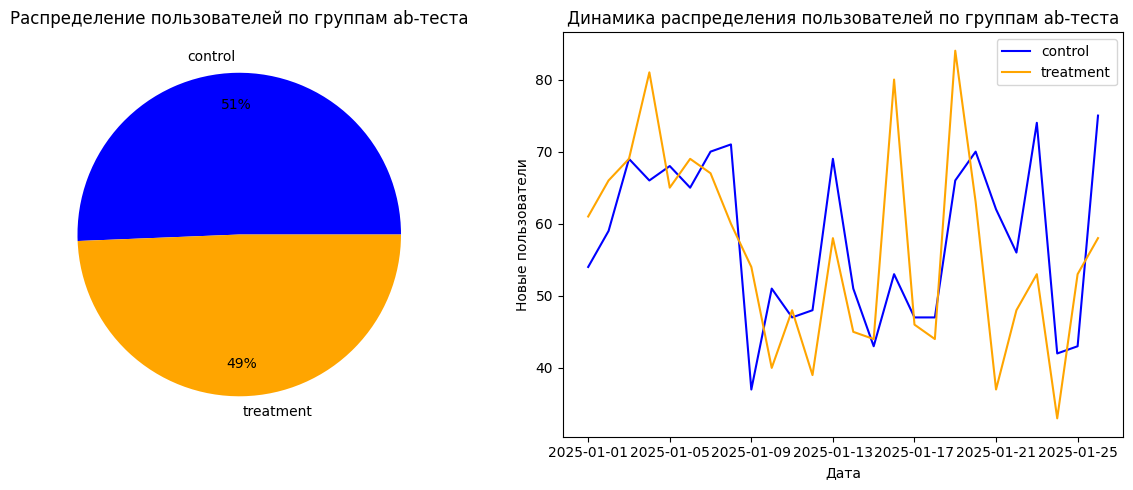

In [96]:
# построим диаграмму распределения пользователей по группам
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

group_colors = {'control': 'blue', 'treatment': 'orange'}

ax[0].pie(users_count_group['user_id'],
    labels=users_count_group['group'],
    autopct='%.0f%%',
    # autopct=lambda pct: absolute_value(pct, users_count_group['user_id'].values),
     pctdistance=0.8,
     labeldistance=1.1,
     colors=get_colors(users_count_group['group'].unique(), group_colors))

ax[0].set_title('Распределение пользователей по группам ab-теста')

for group in users_count_dynamic['group'].unique():
    plot_df = users_count_dynamic.loc[users_count_dynamic['group'] == group]
    ax[1].plot(plot_df['registration_date'], plot_df['users_count_dynamic'],
               label=f'{group}', color=group_colors[group])
    
ax[1].legend()
ax[1].set_xlabel('Дата')
ax[1].set_ylabel('Новые пользователи')
ax[1].set_title('Динамика распределения пользователей по группам ab-теста')

plt.tight_layout()
plt.show()

Распределение пользователей 51 % в контрольной группе против 49 % в тестовой. В динамике есть небольшие расхождения набора групп. Проведем проверку SRM с помощью χ² - теста.

In [97]:
n_a = users_count_group.loc[users_count_group['group'] == "control"]['user_id'].reset_index(drop=True)[0]
n_b = users_count_group.loc[users_count_group['group'] == "treatment"]['user_id'].reset_index(drop=True)[0]

expected_ratios = [0.5, 0.5]
observed_counts = [n_a, n_b]

# Расчёт χ²-статистики
chi2, p_value = chisquare(f_obs=observed_counts, f_exp=[sum(observed_counts) * r for r in expected_ratios])

print(f"χ²: {chi2:1.2f}, p-value: {p_value:1.2f}")

χ²: 0.49, p-value: 0.49


P-value >> 0.001 - распределение пользователей по группам случайное.

### <a id="ab_metrics_verification"></a> Проверка метрик эксперимента

In [98]:
# создадим вспомагательный датафрейм с заказами с указанием группы пользователя
pa_marketplace_orders_AB_group = pa_marketplace_orders_AB.merge(pa_marketplace_AB_split_users, on='user_id', how='inner')

In [99]:
# рассчитаем CR в покупку по группам
order_users_count_ab = pa_marketplace_orders_AB_group.groupby('group').agg(ordering_users=('user_id', 'nunique')).reset_index()
users_count_ab = pa_marketplace_AB_split_users.groupby('group').agg(users=('user_id', 'nunique')).reset_index()

mean_cr_ab = pd.merge(order_users_count_ab, users_count_ab, on='group')

mean_cr_ab['cr'] = 100 * mean_cr_ab['ordering_users'] / mean_cr_ab['users']

In [100]:
# выведем CR по группам
round(mean_cr_ab, 1)

,group,ordering_users,users,cr
0,control,16,1503,1.1
1,treatment,110,1465,7.5


CR в покупку выше в тестовой группе: 7.5 % в тесте против 1.1 в контроле. Проверим статистическую значимость этого результата.
<br><br>
Сформулируем гипотезу:<br>
- H<sub>0</sub>: Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, не приведет к увеличению конверсии в покупку
- H<sub>1</sub>: Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в покупку

In [101]:
# проведем проверку достаточности данных для z-теста пропорций
n_a = mean_cr_ab.loc[mean_cr_ab['group'] == 'control']['users'].values
n_b = mean_cr_ab.loc[mean_cr_ab['group'] == 'treatment']['users'].values

m_a = mean_cr_ab.loc[mean_cr_ab['group'] == 'control']['ordering_users'].values
m_b = mean_cr_ab.loc[mean_cr_ab['group'] == 'treatment']['ordering_users'].values

p_a = m_a / n_a
p_b = m_b / n_b

# проверим предпосылку о достаточном количестве данных
if (p_a*n_a > 10) and ((1-p_a)*n_a > 10) and (p_b*n_b > 10) and ((1-p_b)*n_b > 10):
    print('Предпосылка о достаточном количестве данных выполняется!')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется!')

Предпосылка о достаточном количестве данных выполняется!


In [102]:
# зададим уровень статистической значимости
alpha = 0.05

# проведем проверку статистической значимости увеличения конверсии в покупку в группах ab-теста
cr_ztest, cr_p_value_ztest = proportions_ztest(
    [m_a, m_b],
    [n_a, n_b],
    alternative='smaller'
)

print(f'pvalue={cr_p_value_ztest}') 

if cr_p_value_ztest > alpha:
    print('Нулевая гипотеза находит подтверждение!')
    text_interpretation = 'не увеличилась'
else:
    print('Нулевая гипотеза не находит подтверждения!')
    text_interpretation = 'увеличилась'

print(f'При предоставлении бонуса на первую покупку новым пользователям, привлеченным через TikTok, конверсия к покупку {text_interpretation}.')

pvalue=[1.58245289e-18]
Нулевая гипотеза не находит подтверждения!
При предоставлении бонуса на первую покупку новым пользователям, привлеченным через TikTok, конверсия к покупку увеличилась.


Увеличение CR в покупку с 1.1 % до 7.5 % при предоставлении бонуса на первую покупку новым пользователям является статистически значимым результатом.
___
Проверим, как ведет себя барьерная метрика - общая выручка:

In [103]:
# рассчитаем общую выручку по группам ab-теста
group_revenue = pa_marketplace_orders_AB_group.groupby('group').agg(
    group_revenue=('order_revenue', 'sum')
).reset_index()

In [104]:
# выведем общую выручку по группам
round(group_revenue, 0)

,group,group_revenue
0,control,18919.0
1,treatment,192280.0


Общая выручка в тесте выше - 192000 против 19000 в контроле. Применение бонуса привело к десятикратному увеличению общей выручки. Увеличение барьерной метрики в совокупности с ростом ключевой метрики позволяет говорить, что эксперимент оказался успешным.

___
Проверим дополнительные эффекты на вспомогательных метриках.

In [105]:
# Расcчитаем ARPU по группам
arpu_ab = users_count_ab.merge(group_revenue, on='group')
arpu_ab['ARPU'] = arpu_ab['group_revenue'] / arpu_ab['users']

#рассчитаем ARPPU по группам
arppu_ab = order_users_count_ab.merge(group_revenue, on='group')
arppu_ab['ARPPU'] = arppu_ab['group_revenue'] / arppu_ab['ordering_users']

#рассчитаем AOV по группам
aov_ab = pa_marketplace_orders_AB_group.groupby(['group', 'user_id', 'order_date'])['total_price'].sum().reset_index()
aov_ab = aov_ab.groupby('group').agg(aov=('total_price', 'mean')).reset_index()

# объединим датафреймы
sup_metrics = pd.merge(pd.merge(arpu_ab, arppu_ab, on='group'), aov_ab, on='group')

In [106]:
# Выведем вспомогательные метрики по группам
round(sup_metrics[['group', 'ARPU', 'ARPPU', 'aov']], 0)

,group,ARPU,ARPPU,aov
0,control,13.0,1182.0,21021.0
1,treatment,131.0,1748.0,32590.0


Все три вспомагательные метрики выросли в результате эксперимента:
- ARPU вырос с 13 до 131 - в 10 раз;
- ARPPU вырос с 1200 до 1750 - на 46 %;
- AOV вырос с 21000 до 32500 - на 55 %.

___
Проверим статистическую значимость изменений вспомогателных метрик.

In [107]:
arppu_ab = pa_marketplace_orders_AB_group.groupby(['group', 'user_id']).agg(
    total_revenue=('order_revenue', 'sum')
).reset_index()

In [108]:
# проверим статистическую значимость различий ключевой метрики в группах ab-теста
control_arppu = arppu_ab.loc[arppu_ab['group'] == 'control']['total_revenue'].tolist()

test_arppu = arppu_ab.loc[arppu_ab['group'] == 'treatment']['total_revenue'].tolist()

stat_ttest, p_value_ttest = ttest_ind(control_arppu,
                                     test_arppu,
                                     alternative='less',
                                     equal_var=False)

if p_value_ttest>alpha:
    print(f'p-value теста Стьюдента = {p_value_ttest}')
    print('Нулевая гипотеза находит подтверждение! Выборочная средняя выручка на платящего пользователя в контрольной группе не больше, чем в тестовой')
    print('Интерпретация: бонус для новых пользователей не увеличил среднюю выручку на платящего пользователя')
else:
    print(f'p-value теста Стьюдента = {p_value_ttest}')
    print('Нулевая гипотеза не находит подтверждение! Выборочная средняя выручка на платящего пользователя в контрольной группе больше, чем в тестовой')
    print('Интерпретация: бонус для новых пользователей увеличил среднюю выручку на платящего пользователя')

p-value теста Стьюдента = 0.02463838222198889
Нулевая гипотеза не находит подтверждение! Выборочная средняя выручка на платящего пользователя в контрольной группе больше, чем в тестовой
Интерпретация: бонус для новых пользователей увеличил среднюю выручку на платящего пользователя


In [109]:
arpu_ab = pa_marketplace_orders_AB_group.groupby(['group', 'user_id']).agg(
    total_revenue=('order_revenue', 'sum')
).reset_index()

arpu_ab = arpu_ab.merge(pa_marketplace_AB_split_users, on=['user_id', 'group'], how='outer')

arpu_ab = arpu_ab.fillna(0)

In [110]:
control_arpu = arpu_ab.loc[arpu_ab['group'] == 'control']['total_revenue'].tolist()

test_arpu = arpu_ab.loc[arpu_ab['group'] == 'treatment']['total_revenue'].tolist()

stat, p_value = mannwhitneyu(control_arpu, test_arpu, alternative='less')

if p_value_ttest>alpha:
    print(f'p-value теста Манна-Уитни = {p_value}')
    print('Нулевая гипотеза находит подтверждение! Распределение выручки пользователей в тестовой группе не смещено влево относительно контрольной группы')
    print('Интерпретация: бонус для новых пользователей не увеличил среднюю выручку на пользователя')
else:
    print(f'p-value теста Манна-Уитни = {p_value}')
    print('Нулевая гипотеза не находит подтверждения! Распределение выручки пользователей в тестовой группе смещено влево относительно контрольной группы')
    print('Интерпретация: бонус для новых пользователей увеличил среднюю выручку на пользователя')

p-value теста Манна-Уитни = 1.766304400953675e-18
Нулевая гипотеза не находит подтверждения! Распределение выручки пользователей в тестовой группе смещено влево относительно контрольной группы
Интерпретация: бонус для новых пользователей увеличил среднюю выручку на пользователя


In [111]:
aov_ab = pa_marketplace_orders_AB_group.groupby(['group', 'user_id', 'order_date']).agg(
    total_revenue=('order_revenue', 'sum')
).reset_index()

In [112]:
# проверим статистическую значимость различий ключевой метрики в группах ab-теста
control_aov = arppu_ab.loc[arppu_ab['group'] == 'control']['total_revenue'].tolist()

test_aov = arppu_ab.loc[arppu_ab['group'] == 'treatment']['total_revenue'].tolist()

stat_ttest, p_value_ttest = ttest_ind(control_aov,
                                     test_aov,
                                     alternative='two-sided',
                                     equal_var=False)

if p_value_ttest>alpha:
    print(f'p-value теста Стьюдента = {p_value_ttest}')
    print('Нулевая гипотеза находит подтверждение! Выборочный средний чек не отличается в контрольной и тестовой группах')
    print('Интерпретация: бонус для новых пользователей не изменил средний чек')
else:
    print(f'p-value теста Стьюдента = {p_value_ttest}')
    print('Нулевая гипотеза не находит подтверждения! Выборочный средний чек отличается в контрольной и тестовой группах')
    print('Интерпретация: бонус для новых пользователей изменил средний чек')

p-value теста Стьюдента = 0.04927676444397778
Нулевая гипотеза не находит подтверждения! Выборочный средний чек отличается в контрольной и тестовой группах
Интерпретация: бонус для новых пользователей изменил средний чек


Для всех вспомагательных метрик их рост является статистически значимым результатом.

### <a id="ab_test_conclusion"> Вывод по эксперименту с бонусом на первую покупку для пользователей TikTok 

- Анализ данных эксперимента показал, что эксперимент проведен корректно. Так, пользователи теста равномерно распределены по группам, хотя в динамике распределения есть отклонения между группами, что нормально с учетом малого кол-ва новых пользователей в день.
- Наблюдается увеличение ключевой метрки - CR в покупку - с 1.1 % до 7.5 %. Проверка стат. значимости результата с использованием z-теста пропорций показала, что увеличение CR при предоставлении бонуса на первую покупку новым пользователям является статистически значимым результатом.
- Общая выручка в тесте выше - 192000 против 19000 в контроле. Применение бонуса привело к десятикратному увеличению общей выручки. Увеличение барьерной метрики в совокупности с ростом ключевой метрики позволяет говорить, что эксперимент оказался успешным.
- Все три вспомогательные метрики выросли в результате эксперимента - изменение метрики является статистически значимым результатом для всех метрик с уровнем значимости 5 %. Так, ARPU вырос с 13 до 131 - в 10 раз, ARPPU вырос с 1200 до 1750 - на 46 %, AOV вырос с 21000 до 32500 - на 55 %. Применение бонуса привело к тому, что пользователи стали больше тратить на покупки.
- Эксперимент оказался успешным, рекомендую к реализации в продукте.